In [2]:
from pathlib import Path
from IPython.display import display

#### Définir les chemins sans modifier les données sources
DANS_COLAB = Path('/content').is_dir()
racine_projet = Path.cwd()
if not DANS_COLAB and racine_projet.name == 'notebooks':
    racine_projet = racine_projet.parent

DOSSIER_DONNEES = Path('/content') if DANS_COLAB else racine_projet / 'data' / 'raw'
DOSSIER_SORTIES = (Path('/content') / 'outputs_classification'
                    if DANS_COLAB else racine_projet / 'results' / 'classification')
FICHIER_EXISTANT = DOSSIER_DONNEES / 'dpe03existant (3).csv'
FICHIER_NEUF = DOSSIER_DONNEES / 'dpe02neuf (3).csv'

for fichier in [FICHIER_EXISTANT, FICHIER_NEUF]:
    if not fichier.is_file():
        raise FileNotFoundError(f'CSV brut absent : {fichier}. Adapter les chemins ci-dessus.')
DOSSIER_SORTIES.mkdir(parents=True, exist_ok=True)
print('Résultats et figures :', DOSSIER_SORTIES)


Résultats et figures : /content/outputs_classification


In [3]:
import pandas as pd

#### 1. Lire les deux extractions brutes complètes
df_existant_brut = pd.read_csv(
    FICHIER_EXISTANT,
    low_memory=False
)

df_neuf_brut = pd.read_csv(
    FICHIER_NEUF,
    low_memory=False
)

#### 2. Vérifier les dimensions après rechargement
print("EXISTANT :", df_existant_brut.shape)
print("NEUF     :", df_neuf_brut.shape)

#### 3. Arrêter si le nombre de lignes ne correspond pas aux fichiers attendus
if len(df_existant_brut) != 10000 or len(df_neuf_brut) != 10000:
    raise ValueError(
        "Le chargement ne donne pas 10 000 lignes par fichier."
    )

#### 4. Recalculer les principaux contrôles sur les données rechargées
for nom, df in [
    ("EXISTANT", df_existant_brut),
    ("NEUF", df_neuf_brut)
]:
    print(f"\n--- {nom} ---")

    print("\nÉtiquettes DPE :")
    display(
        df["etiquette_dpe"]
        .value_counts(dropna=False)
        .sort_index()
        .rename("effectif")
        .to_frame()
    )

    print("Étiquettes manquantes :", df["etiquette_dpe"].isna().sum())
    print("Identifiants manquants :", df["numero_dpe"].isna().sum())
    print(
        "Identifiants répétés :",
        df["numero_dpe"].dropna().duplicated().sum()
    )

    print("\nTypes de bâtiments :")
    display(df["type_batiment"].value_counts(dropna=False).to_frame())

    #### Conversion locale pour afficher les codes, sans modifier les données
    departements = (
        df["code_departement_ban"]
        .astype("string")
        .str.strip()
        .str.replace(r"\.0$", "", regex=True)
        .replace("", pd.NA)
    )

    print("Départements renseignés distincts :", departements.nunique())
    print("Départements manquants :", departements.isna().sum())

    print("\nLes 10 départements les plus présents :")
    display(departements.value_counts().head(10).to_frame())

#### 5. Vérifier les identifiants communs aux deux sources
identifiants_communs = (
    set(df_existant_brut["numero_dpe"].dropna())
    & set(df_neuf_brut["numero_dpe"].dropna())
)

print("\nIdentifiants communs aux deux fichiers :", len(identifiants_communs))

EXISTANT : (10000, 226)
NEUF     : (10000, 208)

--- EXISTANT ---

Étiquettes DPE :


,effectif
etiquette_dpe,
A,184
B,631
C,3692
D,3053
E,1572
F,569
G,299


Étiquettes manquantes : 0
Identifiants manquants : 0
Identifiants répétés : 0

Types de bâtiments :


,count
type_batiment,
appartement,6346
maison,3335
immeuble,319


Départements renseignés distincts : 96
Départements manquants : 1067

Les 10 départements les plus présents :


...

Étiquettes manquantes : 0
Identifiants manquants : 0
Identifiants répétés : 0

Types de bâtiments :


,count
type_batiment,
appartement,5294
maison,4531
immeuble,175


Départements renseignés distincts : 94
Départements manquants : 1621

Les 10 départements les plus présents :


,count
code_departement_ban,
14,1328
85,667
49,625
80,293
42,287
38,273
31,246
93,226
44,225



Identifiants communs aux deux fichiers : 0


Colonnes communes après harmonisation : 206

Colonnes propres à l'existant : ['apport_interne_saison_chauffe', 'apport_interne_saison_froide', 'apport_solaire_saison_chauffe', 'apport_solaire_saison_froide', 'date_installation_generateur_n1_ecs_n1', 'date_installation_generateur_n2_ecs_n1', 'description_generateur_chauffage_n1_installation_n1', 'description_generateur_chauffage_n1_installation_n2', 'description_generateur_chauffage_n2_installation_n1', 'description_generateur_chauffage_n2_installation_n2', 'facteur_couverture_solaire_installation_chauffage_n1', 'facteur_couverture_solaire_installation_chauffage_n2', 'facteur_couverture_solaire_n1', 'facteur_couverture_solaire_saisi_installation_chauffage_n1', 'facteur_couverture_solaire_saisi_installation_chauffage_n2', 'facteur_couverture_solaire_saisi_n1', 'periode_installation_generateur_froid', 'qualite_isolation_plancher_haut_comble_perdu', 'qualite_isolation_plancher_haut_toit_terrasse', 'type_energie_climatisation']

Colonnes pr

etiquette_dpe,A,B,C,D,E,F,G
source_dpe,,,,,,,
existant,184,631,3692,3053,1572,569,299
neuf,4844,2162,2983,5,1,1,4


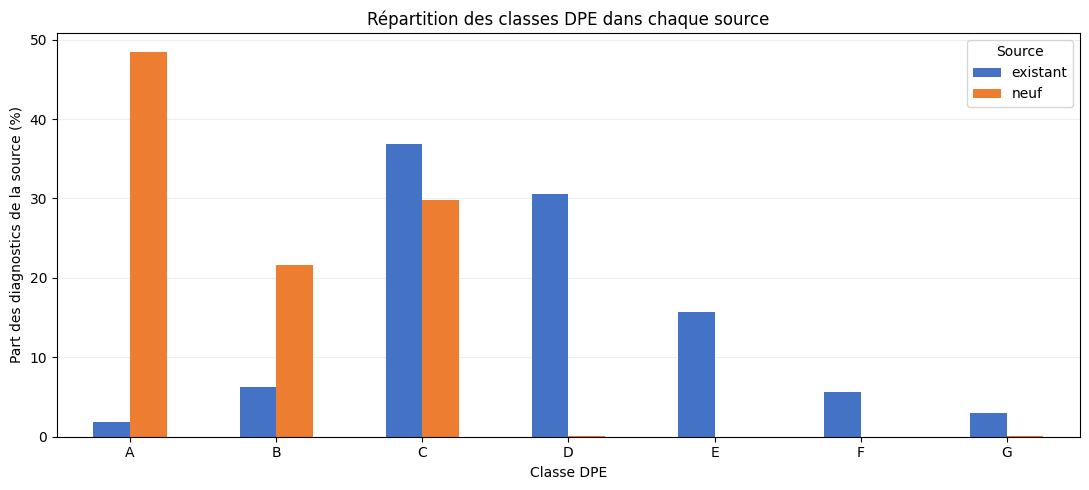


Nombre de colonnes entièrement vides : 11
['facteur_couverture_solaire_saisi_installation_chauffage_n1', 'facteur_couverture_solaire_installation_chauffage_n2', 'facteur_couverture_solaire_saisi_installation_chauffage_n2', 'type_generateur_n2_ecs_n1', 'type_energie_generateur_n2_ecs_n1', 'usage_generateur_n2_ecs_n1', 'description_generateur_n2_ecs_n1', 'volume_stockage_generateur_n2_ecs_n1', 'cop_generateur_n2_ecs_n1', 'conso_ef_generateur_n2_ecs_n1', 'date_installation_generateur_n2_ecs_n1']


In [4]:
import re
import matplotlib.pyplot as plt

#### 1. Harmoniser les noms des colonnes dans des copies
def harmoniser_colonnes(df):
    resultat = df.copy()

    resultat.columns = [
        re.sub(r"\s+", "_", str(colonne).strip().lower())
        for colonne in resultat.columns
    ]

    #### Vérifier que deux colonnes ne deviennent pas identiques
    doublons = resultat.columns[
        resultat.columns.duplicated()
    ].tolist()

    if doublons:
        raise ValueError(
            f"Noms de colonnes dupliqués après harmonisation : {doublons}"
        )

    return resultat


df_existant_h = harmoniser_colonnes(df_existant_brut)
df_neuf_h = harmoniser_colonnes(df_neuf_brut)

#### 2. Comparer les colonnes après harmonisation
colonnes_existantes = set(df_existant_h.columns)
colonnes_neuves = set(df_neuf_h.columns)

print(
    "Colonnes communes après harmonisation :",
    len(colonnes_existantes & colonnes_neuves)
)

print(
    "\nColonnes propres à l'existant :",
    sorted(colonnes_existantes - colonnes_neuves)
)

print(
    "\nColonnes propres au neuf :",
    sorted(colonnes_neuves - colonnes_existantes)
)

#### 3. Réunir les sources en conservant leur origine
df_dpe = pd.concat(
    [
        df_existant_h.assign(source_dpe="existant"),
        df_neuf_h.assign(source_dpe="neuf")
    ],
    ignore_index=True,
    sort=False
)

print("\nDimensions réunies :", df_dpe.shape)

#### 4. Afficher les effectifs de chaque classe par source
ordre_classes = list("ABCDEFG")
ordre_sources = ["existant", "neuf"]

effectifs_dpe = pd.crosstab(
    df_dpe["source_dpe"],
    df_dpe["etiquette_dpe"]
).reindex(
    index=ordre_sources,
    columns=ordre_classes,
    fill_value=0
)

print("\nEffectifs par source et par classe :")
display(effectifs_dpe)

#### 5. Comparer les proportions dans chaque source
proportions_dpe = (
    effectifs_dpe
    .div(effectifs_dpe.sum(axis=1), axis=0)
    .mul(100)
)

ax = proportions_dpe.T.plot(
    kind="bar",
    figsize=(11, 5),
    color=["#4472C4", "#ED7D31"],
    rot=0
)

ax.set_title("Répartition des classes DPE dans chaque source")
ax.set_xlabel("Classe DPE")
ax.set_ylabel("Part des diagnostics de la source (%)")
ax.legend(title="Source")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(
    str(DOSSIER_SORTIES / 'repartition_dpe_sources.png'),
    dpi=150,
    bbox_inches="tight"
)
plt.show()

#### 6. Repérer les colonnes entièrement vides sur les deux sources
colonnes_vides = df_dpe.columns[
    df_dpe.isna().all()
].tolist()

print("\nNombre de colonnes entièrement vides :", len(colonnes_vides))
print(colonnes_vides)

Étiquettes manquantes ou invalides : 0

Diagnostics au départ : 20000
Diagnostics hors périmètre : 494
Logements conservés : 19506

Logements conservés par source :


type_batiment,appartement,maison
source_dpe,,
existant,6346,3335
neuf,5294,4531



Colonnes entièrement vides retirées : 11
['facteur_couverture_solaire_saisi_installation_chauffage_n1', 'facteur_couverture_solaire_installation_chauffage_n2', 'facteur_couverture_solaire_saisi_installation_chauffage_n2', 'type_generateur_n2_ecs_n1', 'type_energie_generateur_n2_ecs_n1', 'usage_generateur_n2_ecs_n1', 'description_generateur_n2_ecs_n1', 'volume_stockage_generateur_n2_ecs_n1', 'cop_generateur_n2_ecs_n1', 'conso_ef_generateur_n2_ecs_n1', 'date_installation_generateur_n2_ecs_n1']

Dimensions après cette étape : (19506, 218)

Les 25 colonnes les plus incomplètes :


,manquants_global_%,valeurs_distinctes,manquants_existant_%,manquants_neuf_%
variable,,,,
facteur_couverture_solaire_saisi_n1,100.0,4,99.9,100.0
numero_rpls_logement,99.9,16,99.8,100.0
facteur_couverture_solaire_installation_chauffage_n1,99.9,3,99.8,100.0
surface_tertiaire_immeuble,99.8,7,99.7,99.9
type_generateur_n2_installation_n2,99.7,22,99.3,100.0
usage_generateur_n2_installation_n2,99.7,1,99.3,100.0
type_energie_generateur_n2_installation_n2,99.7,4,99.3,100.0
conso_chauffage_generateur_n2_installation_n2,99.7,65,99.3,100.0
description_generateur_chauffage_n2_installation_n2,99.7,30,99.3,100.0


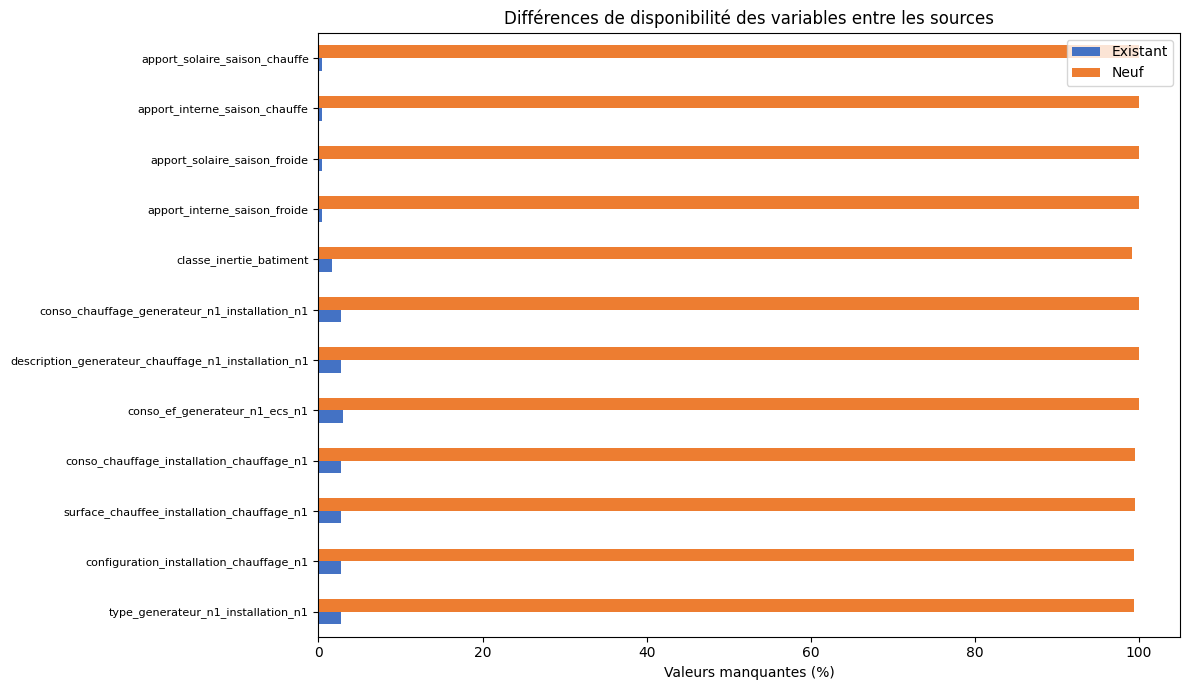

In [5]:
#### 1. Nettoyer les espaces dans les textes en conservant la table complète
df_travail = df_dpe.copy()

colonnes_texte = df_travail.select_dtypes(
    include=["object", "string"]
).columns

for colonne in colonnes_texte:
    df_travail[colonne] = (
        df_travail[colonne]
        .astype("string")
        .str.strip()
        .replace("", pd.NA)
    )

#### 2. Harmoniser la cible et les types de bâtiments
df_travail["etiquette_dpe"] = (
    df_travail["etiquette_dpe"].str.upper()
)

df_travail["type_batiment"] = (
    df_travail["type_batiment"].str.lower()
)

#### 3. Vérifier que toutes les étiquettes appartiennent à A–G
cibles_invalides = ~df_travail["etiquette_dpe"].isin(list("ABCDEFG"))

print("Étiquettes manquantes ou invalides :", cibles_invalides.sum())

if cibles_invalides.any():
    display(
        df_travail.loc[
            cibles_invalides,
            ["numero_dpe", "source_dpe", "etiquette_dpe"]
        ]
    )
    raise ValueError("Examiner ces étiquettes avant de continuer.")

#### 4. Séparer les logements individuels des autres diagnostics
masque_logements = df_travail["type_batiment"].isin(
    ["maison", "appartement"]
)

df_hors_perimetre = df_travail.loc[~masque_logements].copy()
df_logements = df_travail.loc[masque_logements].copy()

#### La table complète reste disponible pour relier les diagnostics par bâtiment
print("\nDiagnostics au départ :", len(df_travail))
print("Diagnostics hors périmètre :", len(df_hors_perimetre))
print("Logements conservés :", len(df_logements))

print("\nLogements conservés par source :")
display(
    pd.crosstab(
        df_logements["source_dpe"],
        df_logements["type_batiment"]
    )
)

#### 5. Retirer de la table des logements les colonnes entièrement vides
colonnes_vides_logements = df_logements.columns[
    df_logements.isna().all()
].tolist()

df_logements = df_logements.drop(columns=colonnes_vides_logements)

print("\nColonnes entièrement vides retirées :", len(colonnes_vides_logements))
print(colonnes_vides_logements)
print("\nDimensions après cette étape :", df_logements.shape)

#### 6. Mesurer les valeurs manquantes, globalement et par source
profil_manquants = pd.DataFrame({
    "manquants_global_%": df_logements.isna().mean().mul(100),
    "valeurs_distinctes": df_logements.nunique(dropna=True)
})

for source in ["existant", "neuf"]:
    sous_table = df_logements.loc[
        df_logements["source_dpe"].eq(source)
    ]

    profil_manquants[f"manquants_{source}_%"] = (
        sous_table.isna().mean().mul(100)
    )

profil_manquants.index.name = "variable"

print("\nLes 25 colonnes les plus incomplètes :")
display(
    profil_manquants
    .sort_values("manquants_global_%", ascending=False)
    .head(25)
    .round(1)
)

#### 7. Visualiser les différences de disponibilité entre les sources
ecart_disponibilite = (
    profil_manquants["manquants_existant_%"]
    - profil_manquants["manquants_neuf_%"]
).abs()

variables_a_tracer = (
    ecart_disponibilite
    .sort_values(ascending=False)
    .head(12)
    .index
)

ax = profil_manquants.loc[
    variables_a_tracer,
    ["manquants_existant_%", "manquants_neuf_%"]
].iloc[::-1].plot(
    kind="barh",
    figsize=(12, 7),
    color=["#4472C4", "#ED7D31"]
)

ax.set_title("Différences de disponibilité des variables entre les sources")
ax.set_xlabel("Valeurs manquantes (%)")
ax.set_ylabel("")
ax.set_xlim(0, 105)
ax.legend(["Existant", "Neuf"])
ax.tick_params(axis="y", labelsize=8)

plt.tight_layout()
plt.savefig(
    str(DOSSIER_SORTIES / 'disponibilite_variables_par_source.png'),
    dpi=150,
    bbox_inches="tight"
)
plt.show()

In [6]:
import numpy as np
from sklearn.model_selection import StratifiedGroupKFold

#### 1. Construire les liens sur les 20 000 diagnostics
#### Les diagnostics d'immeubles peuvent relier plusieurs appartements
parents = np.arange(len(df_travail))
tailles = np.ones(len(df_travail), dtype=int)


def trouver_racine(position):
    while parents[position] != position:
        parents[position] = parents[parents[position]]
        position = parents[position]
    return position


def relier(position_a, position_b):
    racine_a = trouver_racine(position_a)
    racine_b = trouver_racine(position_b)

    if racine_a == racine_b:
        return

    if tailles[racine_a] < tailles[racine_b]:
        racine_a, racine_b = racine_b, racine_a

    parents[racine_b] = racine_a
    tailles[racine_a] += tailles[racine_b]


#### 2. Utiliser les identifiants et les adresses pour détecter les liens
#### Les références à un autre DPE partagent la même famille d'identifiants
champs_liens = {
    "numero_dpe": "dpe",
    "numero_dpe_immeuble_associe": "dpe",
    "numero_dpe_remplace": "dpe",
    "id_rnb": "rnb",
    "identifiant_ban": "identifiant_ban",
    "adresse_ban": "adresse_ban"
}

valeurs_a_ignorer = {
    "", "nan", "none", "null", "<na>", "0", "non renseigné"
}

premiere_position = {}

for colonne, famille in champs_liens.items():
    if colonne not in df_travail.columns:
        continue

    for position, valeur in enumerate(df_travail[colonne]):
        if pd.isna(valeur):
            continue

        valeur_normalisee = re.sub(
            r"\s+", " ", str(valeur).strip().casefold()
        )

        if valeur_normalisee in valeurs_a_ignorer:
            continue

        cle = (famille, valeur_normalisee)

        if cle in premiere_position:
            relier(position, premiere_position[cle])
        else:
            premiere_position[cle] = position

#### 3. Attribuer un groupe à chaque diagnostic
racines = pd.Series(
    [trouver_racine(i) for i in range(len(df_travail))],
    index=df_travail.index
)

groupes_complets = pd.Series(
    pd.factorize(racines, sort=False)[0],
    index=df_travail.index,
    name="groupe"
)

#### Conserver les groupes correspondant aux maisons et appartements
groupes = groupes_complets.loc[df_logements.index]
tailles_groupes = groupes.value_counts()

print("Logements :", len(df_logements))
print("Groupes détectés :", groupes.nunique())
print("Plus grand groupe :", tailles_groupes.max())
print("Les 10 plus grands groupes :", tailles_groupes.head(10).tolist())

#### 4. Définir une partition fixe par groupes
#### La stratification cherche à préserver la répartition des classes A–G
separation = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

indices_app, indices_test = next(
    separation.split(
        df_logements,
        y=df_logements["etiquette_dpe"],
        groups=groupes
    )
)

df_app = df_logements.iloc[indices_app].copy()
df_test = df_logements.iloc[indices_test].copy()

groupes_app = groupes.iloc[indices_app]
groupes_test = groupes.iloc[indices_test]

#### 5. Vérifier la séparation des groupes
groupes_partages = set(groupes_app) & set(groupes_test)

print("\nApprentissage :", df_app.shape)
print("Test final :", df_test.shape)
print("Groupes partagés :", len(groupes_partages))

if groupes_partages:
    raise ValueError("Des groupes sont présents dans les deux ensembles.")

#### 6. Examiner la répartition des classes et des sources
for nom, table in [
    ("APPRENTISSAGE", df_app),
    ("TEST FINAL", df_test)
]:
    print(f"\n--- {nom} ---")
    display(
        pd.crosstab(
            table["source_dpe"],
            table["etiquette_dpe"]
        ).reindex(columns=list("ABCDEFG"), fill_value=0)
    )

#### 7. Enregistrer la partition commune aux deux méthodes
partition_commune = df_logements[
    ["numero_dpe", "source_dpe", "etiquette_dpe"]
].copy()

partition_commune["groupe"] = groupes
partition_commune["partition"] = "apprentissage"

partition_commune.loc[df_test.index, "partition"] = "test_final"

partition_commune.to_csv(
    str(DOSSIER_SORTIES / 'partition_commune_dpe.csv'),
    index=False
)

print("\nPartition enregistrée : partition_commune_dpe.csv")

Logements : 19506
Groupes détectés : 12180
Plus grand groupe : 130
Les 10 plus grands groupes : [130, 77, 71, 70, 66, 60, 59, 58, 57, 57]

Apprentissage : (15615, 218)
Test final : (3891, 218)
Groupes partagés : 0

--- APPRENTISSAGE ---


etiquette_dpe,A,B,C,D,E,F,G
source_dpe,,,,,,,
existant,145,487,2854,2368,1222,440,230
neuf,3845,1715,2303,5,0,1,0



--- TEST FINAL ---


etiquette_dpe,A,B,C,D,E,F,G
source_dpe,,,,,,,
existant,37,135,729,576,294,105,59
neuf,922,405,629,0,0,0,0



Partition enregistrée : partition_commune_dpe.csv


Contrôle des valeurs numériques :


,renseignees_non_convertibles,valeurs_infinies
variable,,
surface_habitable_logement,0,0
surface_habitable_immeuble,0,0
hauteur_sous_plafond,0,0
annee_construction,0,0
nombre_niveau_logement,0,0
ubat_w_par_m2_k,0,0



Statistiques physiques — apprentissage uniquement :


renseignes  manquants_%  minimum  \
variable                   source_dpe                                     
surface_habitable_logement existant          7746         0.00     7.00   
                           neuf              6313        19.77    16.30   
surface_habitable_immeuble existant          2970        61.66     1.00   
                           neuf              5459        30.63    34.00   
hauteur_sous_plafond       existant          7746         0.00     1.50   
                           neuf              7869         0.00     2.00   
annee_construction         existant          4558        41.16  1634.00   
                           neuf              7869         0.00  2012.00   
nombre_niveau_logement     existant          7746         0.00     1.00   
                           neuf              7189         8.64     1.00   
ubat_w_par_m2_k            existant          7746         0.00     0.10   
                           neuf              7869         0.00     0.02   

                                       percentile_1  mediane  percentile_99  \
variable                   source_dpe                                         
surface_habitable_logement existant           15.59    65.40         241.51   
                           neuf               19.41    65.70         174.93   
surface_habitable_immeuble existant           20.91  1488.40       21467.57   
                           neuf               65.00   967.70        7281.00   
hauteur_sous_plafond       existant            2.20     2.50           3.20   
                           neuf                2.50     2.50           2.80   
annee_construction         existant         1873.71  1978.00        2021.00   
                           neuf             2013.00  2024.00        2026.00   
nombre_niveau_logement     existant            1.00     1.00           4.00   
                           neuf                1.00     1.00           2.00   
ubat_w_par_m2_k            existant            0.20     0.79           2.81   
                           neuf                0.19     0.40           2.47   

                                          maximum  zero_ou_negatif  
variable                   source_dpe                               
surface_habitable_logement existant        675.00                0  
                           neuf           2889.60                0  
surface_habitable_immeuble existant    1000000.00                0  
                           neuf          19999.50                0  
hauteur_sous_plafond       existant         25.00                0  
                           neuf              6.60                0  
annee_construction         existant       2025.00                0  
                           neuf           2027.00                0  
nombre_niveau_logement     existant         84.00                0  
                           neuf              9.00                0  
ubat_w_par_m2_k            existant          5.13                0  
                           neuf             91.18                0

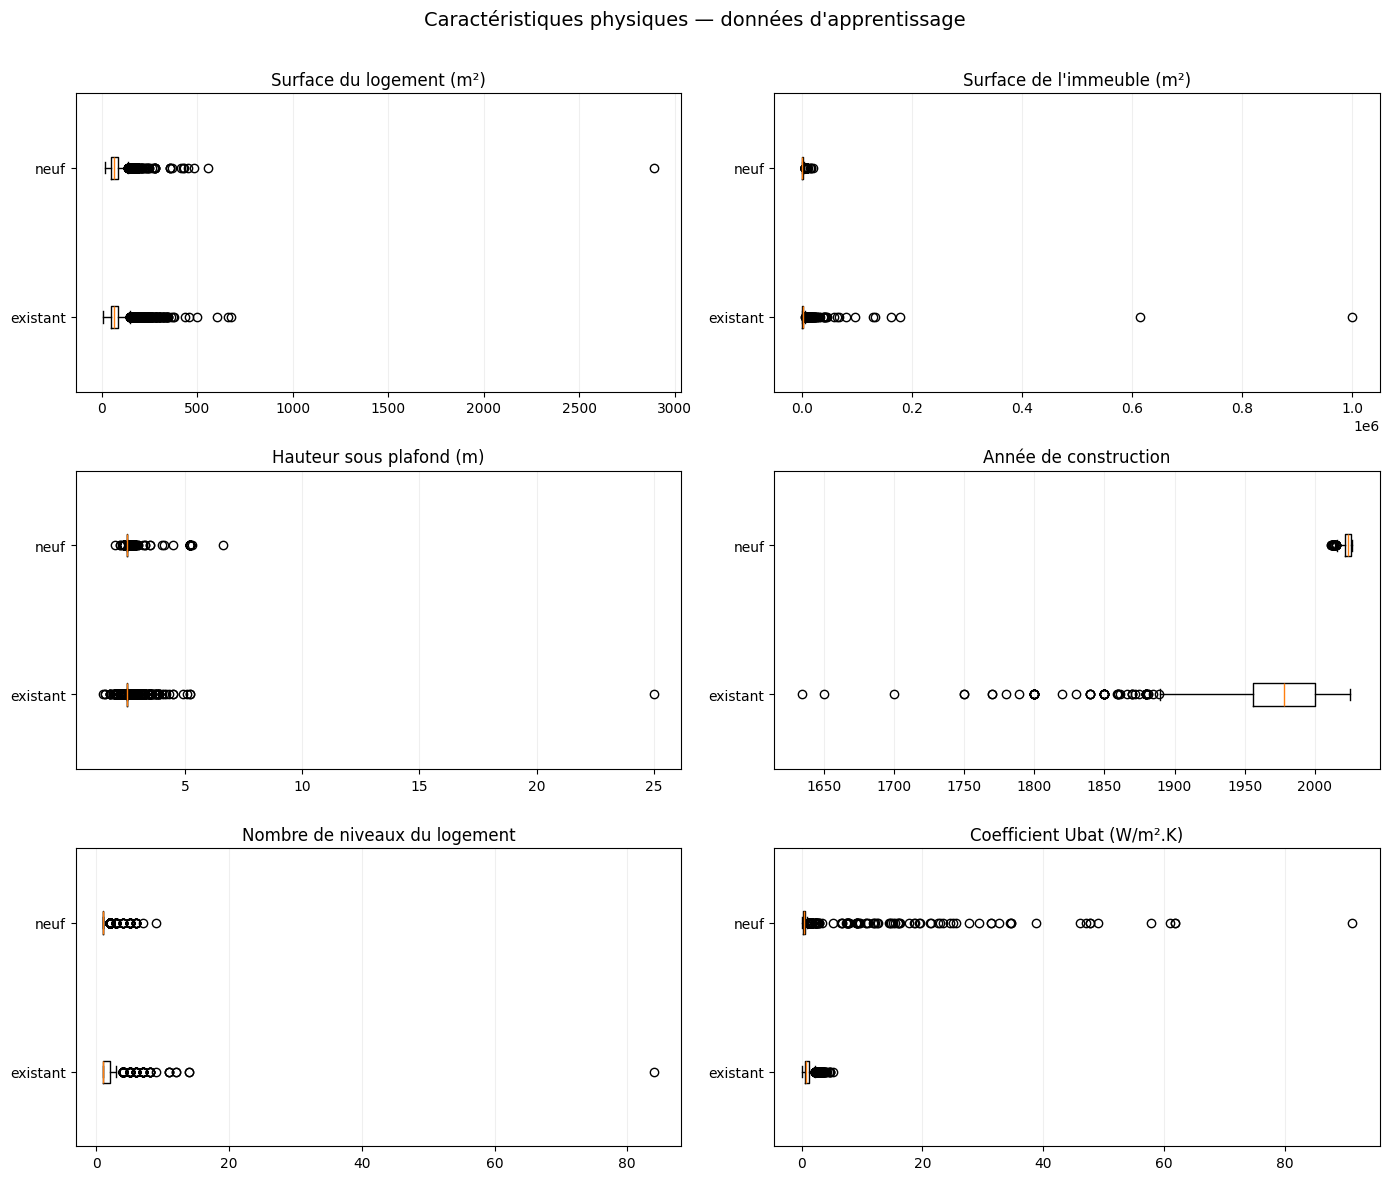

In [7]:
#### 1. Choisir les caractéristiques physiques à examiner
variables_physiques = [
    "surface_habitable_logement",
    "surface_habitable_immeuble",
    "hauteur_sous_plafond",
    "annee_construction",
    "nombre_niveau_logement",
    "ubat_w_par_m2_k"
]

absentes = [
    colonne for colonne in variables_physiques
    if colonne not in df_app.columns
]

if absentes:
    raise ValueError(f"Colonnes absentes : {absentes}")

#### 2. Créer une copie pour l'analyse de l'apprentissage
df_audit_physique = df_app[
    ["source_dpe", "type_batiment"] + variables_physiques
].copy()

#### 3. Contrôler les conversions et les valeurs infinies
controles = []

for colonne in variables_physiques:
    valeurs_originales = df_app[colonne]

    valeurs_numeriques = pd.to_numeric(
        valeurs_originales,
        errors="coerce"
    ).astype("float64")

    non_convertibles = (
        valeurs_originales.notna()
        & valeurs_numeriques.isna()
    )

    valeurs_infinies = np.isinf(valeurs_numeriques)

    controles.append({
        "variable": colonne,
        "renseignees_non_convertibles": int(non_convertibles.sum()),
        "valeurs_infinies": int(valeurs_infinies.sum())
    })

    #### Dans la copie d'analyse, les valeurs infinies deviennent manquantes
    df_audit_physique[colonne] = valeurs_numeriques.replace(
        [np.inf, -np.inf], np.nan
    )

print("Contrôle des valeurs numériques :")
display(pd.DataFrame(controles).set_index("variable"))

#### 4. Décrire les distributions séparément pour chaque source
lignes_statistiques = []

for colonne in variables_physiques:
    for source in ["existant", "neuf"]:
        valeurs = df_audit_physique.loc[
            df_audit_physique["source_dpe"].eq(source),
            colonne
        ]

        valeurs_valides = valeurs.dropna()

        lignes_statistiques.append({
            "variable": colonne,
            "source_dpe": source,
            "renseignes": len(valeurs_valides),
            "manquants_%": valeurs.isna().mean() * 100,
            "minimum": valeurs_valides.min(),
            "percentile_1": valeurs_valides.quantile(0.01),
            "mediane": valeurs_valides.median(),
            "percentile_99": valeurs_valides.quantile(0.99),
            "maximum": valeurs_valides.max(),
            "zero_ou_negatif": int((valeurs_valides <= 0).sum())
        })

statistiques_physiques = (
    pd.DataFrame(lignes_statistiques)
    .set_index(["variable", "source_dpe"])
)

print("\nStatistiques physiques — apprentissage uniquement :")
display(statistiques_physiques.round(2))

#### 5. Visualiser les distributions et les valeurs extrêmes
titres = {
    "surface_habitable_logement": "Surface du logement (m²)",
    "surface_habitable_immeuble": "Surface de l'immeuble (m²)",
    "hauteur_sous_plafond": "Hauteur sous plafond (m)",
    "annee_construction": "Année de construction",
    "nombre_niveau_logement": "Nombre de niveaux du logement",
    "ubat_w_par_m2_k": "Coefficient Ubat (W/m².K)"
}

fig, axes = plt.subplots(3, 2, figsize=(14, 12))

for ax, colonne in zip(axes.flat, variables_physiques):
    sources_presentes = []
    distributions = []

    for source in ["existant", "neuf"]:
        valeurs = df_audit_physique.loc[
            df_audit_physique["source_dpe"].eq(source),
            colonne
        ].dropna()

        if not valeurs.empty:
            sources_presentes.append(source)
            distributions.append(valeurs.to_numpy())

    if distributions:
        ax.boxplot(distributions, vert=False, showfliers=True)
        ax.set_yticks(range(1, len(sources_presentes) + 1))
        ax.set_yticklabels(sources_presentes)
    else:
        ax.text(
            0.5, 0.5, "Aucune valeur exploitable",
            ha="center", va="center", transform=ax.transAxes
        )

    ax.set_title(titres[colonne])
    ax.grid(axis="x", alpha=0.2)

fig.suptitle(
    "Caractéristiques physiques — données d'apprentissage",
    fontsize=14
)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig(
    str(DOSSIER_SORTIES / 'caracteristiques_physiques_apprentissage.png'),
    dpi=150,
    bbox_inches="tight"
)
plt.show()

#### 6. Conserver le bilan pour le rapport
statistiques_physiques.to_csv(
    str(DOSSIER_SORTIES / 'statistiques_physiques_apprentissage.csv')
)

In [8]:
#### 1. Préparer une table de contrôle avec les valeurs numériques vérifiées
controle_physique = df_app.copy()

for colonne in variables_physiques:
    controle_physique[colonne] = df_audit_physique[colonne]

#### 2. Repérer les valeurs à examiner
reperages = pd.DataFrame(index=controle_physique.index)

reperages["surface_logement_superieure_500"] = (
    controle_physique["surface_habitable_logement"] > 500
)

reperages["surface_immeuble_superieure_100000"] = (
    controle_physique["surface_habitable_immeuble"] > 100000
)

reperages["hauteur_inferieure_1_8_ou_superieure_5"] = (
    (controle_physique["hauteur_sous_plafond"] < 1.8)
    | (controle_physique["hauteur_sous_plafond"] > 5)
)

reperages["nombre_niveaux_superieur_10"] = (
    controle_physique["nombre_niveau_logement"] > 10
)

reperages["ubat_inferieur_0_05_ou_superieur_5"] = (
    (controle_physique["ubat_w_par_m2_k"] < 0.05)
    | (controle_physique["ubat_w_par_m2_k"] > 5)
)

#### 3. Compter les cas par source
print("Nombre de cas repérés par source :")
display(
    reperages
    .groupby(controle_physique["source_dpe"])
    .sum()
    .T
)

print(
    "Logements concernés par au moins un contrôle :",
    int(reperages.any(axis=1).sum())
)

#### 4. Examiner les Ubat les plus élevés et les plus faibles
colonnes_ubat = [
    "numero_dpe",
    "source_dpe",
    "type_batiment",
    "ubat_w_par_m2_k",
    "qualite_isolation_enveloppe",
    "qualite_isolation_murs",
    "annee_construction",
    "surface_habitable_logement"
]

colonnes_ubat = [
    colonne for colonne in colonnes_ubat
    if colonne in controle_physique.columns
]

cas_ubat = pd.concat([
    controle_physique.nlargest(8, "ubat_w_par_m2_k"),
    controle_physique.nsmallest(3, "ubat_w_par_m2_k")
]).drop_duplicates("numero_dpe")

print("\nUbat : valeurs extrêmes et caractéristiques associées :")
display(cas_ubat[colonnes_ubat])

#### 5. Examiner les principaux cas de géométrie
cas_geometrie = []

for variable, motif in [
    ("surface_habitable_logement", "Grandes surfaces de logement"),
    ("surface_habitable_immeuble", "Grandes surfaces d'immeuble"),
    ("hauteur_sous_plafond", "Grandes hauteurs sous plafond"),
    ("nombre_niveau_logement", "Nombre élevé de niveaux")
]:
    extrait = controle_physique.nlargest(3, variable).copy()
    extrait["motif_du_controle"] = motif
    cas_geometrie.append(extrait)

cas_geometrie = pd.concat(cas_geometrie)

colonnes_geometrie = [
    "motif_du_controle",
    "numero_dpe",
    "source_dpe",
    "type_batiment",
    "surface_habitable_logement",
    "surface_habitable_immeuble",
    "hauteur_sous_plafond",
    "nombre_niveau_logement",
    "nombre_niveau_immeuble",
    "methode_application_dpe"
]

colonnes_geometrie = [
    colonne for colonne in colonnes_geometrie
    if colonne in cas_geometrie.columns
]

print("\nGéométrie : principaux cas à examiner :")
display(cas_geometrie[colonnes_geometrie])

#### 6. Comprendre les surfaces de logement manquantes
controle_surfaces = controle_physique[
    ["source_dpe", "type_batiment"]
].copy()

controle_surfaces["surface_absente"] = (
    controle_physique["surface_habitable_logement"].isna()
)

controle_surfaces["surface_immeuble_disponible"] = (
    controle_surfaces["surface_absente"]
    & controle_physique["surface_habitable_immeuble"].notna()
)

bilan_surfaces = controle_surfaces.groupby(
    ["source_dpe", "type_batiment"]
).agg(
    effectif=("surface_absente", "size"),
    surfaces_logement_absentes=("surface_absente", "sum"),
    immeuble_renseigne_si_logement_absent=(
        "surface_immeuble_disponible", "sum"
    )
)

print("\nSurfaces manquantes selon le type de bâtiment :")
display(bilan_surfaces)

Nombre de cas repérés par source :


source_dpe,existant,neuf
surface_logement_superieure_500,3,2
surface_immeuble_superieure_100000,6,0
hauteur_inferieure_1_8_ou_superieure_5,7,33
nombre_niveaux_superieur_10,8,0
ubat_inferieur_0_05_ou_superieur_5,1,115


Logements concernés par au moins un contrôle : 175

Ubat : valeurs extrêmes et caractéristiques associées :


variable,numero_dpe,source_dpe,type_batiment,ubat_w_par_m2_k,qualite_isolation_enveloppe,qualite_isolation_murs,annee_construction,surface_habitable_logement
15660,2683N0043039C,neuf,appartement,91.18,insuffisante,bonne,2025.0,45.0
11705,2683N0043059W,neuf,appartement,61.74,insuffisante,bonne,2025.0,46.5
12992,2683N0043094F,neuf,appartement,61.74,insuffisante,bonne,2025.0,46.9
11591,2683N0043072J,neuf,appartement,60.96,insuffisante,bonne,2025.0,45.0
12755,2683N0043623O,neuf,appartement,57.86,insuffisante,bonne,2025.0,60.3
17247,2683N0043634Z,neuf,appartement,49.13,insuffisante,bonne,2025.0,60.5
10987,2683N0043683W,neuf,appartement,47.72,insuffisante,bonne,2025.0,73.1
11294,2683N0043656V,neuf,appartement,47.72,insuffisante,bonne,2025.0,73.0
10131,2607N0026171K,neuf,appartement,0.02,très bonne,très bonne,2025.0,49.6
10366,2607N0026385Q,neuf,appartement,0.02,très bonne,très bonne,2025.0,49.6



Géométrie : principaux cas à examiner :


variable,motif_du_controle,numero_dpe,source_dpe,type_batiment,surface_habitable_logement,surface_habitable_immeuble,hauteur_sous_plafond,nombre_niveau_logement,nombre_niveau_immeuble,methode_application_dpe
12822,Grandes surfaces de logement,2593N4043998M,neuf,maison,2889.6,2889.6,2.5,1.0,1.0,dpe issu d'une étude thermique réglementaire R...
4451,Grandes surfaces de logement,2230E0885750N,existant,maison,675.0,NaN,2.8,3.0,NaN,dpe maison individuelle
9601,Grandes surfaces de logement,2604E0028588X,existant,maison,660.0,NaN,2.9,3.0,NaN,dpe maison individuelle
7907,Grandes surfaces d'immeuble,2691E0002124K,existant,appartement,66.5,1000000.0,2.5,1.0,NaN,dpe appartement individuel
7144,Grandes surfaces d'immeuble,2692E0026644N,existant,appartement,90.1,613793.0,2.5,6.0,NaN,dpe appartement individuel
9068,Grandes surfaces d'immeuble,2669E0011695R,existant,appartement,35.8,178832.0,2.5,1.0,NaN,dpe appartement individuel
1497,Grandes hauteurs sous plafond,2550E1780591J,existant,maison,48.0,NaN,25.0,1.0,1.0,dpe maison individuelle
18476,Grandes hauteurs sous plafond,2217N0671572T,neuf,maison,NaN,NaN,6.6,2.0,2.0,dpe issu d'une étude thermique réglementaire R...
19373,Grandes hauteurs sous plafond,2217N1646872H,neuf,maison,NaN,NaN,5.3,1.0,1.0,dpe issu d'une étude thermique réglementaire R...
2917,Nombre élevé de niveaux,2678E0032131A,existant,appartement,23.0,9252.0,2.7,84.0,NaN,dpe appartement individuel



Surfaces manquantes selon le type de bâtiment :


effectif  surfaces_logement_absentes  \
source_dpe type_batiment                                         
existant   appartement        5100                           0   
           maison             2646                           0   
neuf       appartement        4276                           8   
           maison             3593                        1548   

                          immeuble_renseigne_si_logement_absent  
source_dpe type_batiment                                         
existant   appartement                                        0  
           maison                                             0  
neuf       appartement                                        0  
           maison                                             0

In [9]:
#### 1. Définir une préparation réutilisable pour les deux variantes
def preparer_physique(table, variante="brute"):

    if variante not in ["brute", "controlee"]:
        raise ValueError("Variante attendue : brute ou controlee.")

    resultat = table.copy()
    morceaux_journal = []

    #### Convertir les caractéristiques physiques sans modifier la table initiale
    for colonne in variables_physiques:
        resultat[colonne] = pd.to_numeric(
            resultat[colonne],
            errors="coerce"
        ).astype("float64")

        resultat[colonne] = resultat[colonne].replace(
            [np.inf, -np.inf], np.nan
        )

    #### La version brute conserve les valeurs numériques observées
    if variante == "brute":
        return resultat, pd.DataFrame()

    #### 2. Définir les contrôles expérimentaux
    #### Les grandes surfaces restent conservées faute de preuve suffisante
    niveaux = resultat["nombre_niveau_logement"]

    regles = {
        "surface_habitable_logement": (
            resultat["surface_habitable_logement"] <= 0
        ),

        "surface_habitable_immeuble": (
            resultat["surface_habitable_immeuble"] <= 0
        ),

        "hauteur_sous_plafond": (
            (resultat["hauteur_sous_plafond"] < 1.8)
            | (resultat["hauteur_sous_plafond"] > 5)
        ),

        "nombre_niveau_logement": (
            (niveaux < 1)
            | (niveaux > 10)
            | (niveaux.notna() & (niveaux % 1 != 0))
        ),

        "ubat_w_par_m2_k": (
            (resultat["ubat_w_par_m2_k"] < 0.05)
            | (resultat["ubat_w_par_m2_k"] > 5)
        )
    }

    #### 3. Journaliser chaque modification avant de l'appliquer
    for colonne, masque in regles.items():
        masque = masque.fillna(False)

        if not masque.any():
            continue

        extrait = resultat.loc[
            masque,
            ["numero_dpe", "source_dpe"]
        ].copy()

        extrait["index_origine"] = extrait.index
        extrait["variable"] = colonne
        extrait["valeur_originale"] = resultat.loc[masque, colonne]
        extrait["traitement"] = "Valeur rendue manquante dans la variante"

        morceaux_journal.append(extrait)

        #### Modifier uniquement la valeur concernée
        resultat.loc[masque, colonne] = np.nan

    colonnes_journal = [
        "numero_dpe",
        "source_dpe",
        "index_origine",
        "variable",
        "valeur_originale",
        "traitement"
    ]

    journal = (
        pd.concat(morceaux_journal, ignore_index=True)
        if morceaux_journal
        else pd.DataFrame(columns=colonnes_journal)
    )

    return resultat, journal


#### 4. Préparer les deux versions sur l'apprentissage
df_app_brut, _ = preparer_physique(
    df_app,
    variante="brute"
)

df_app_controle, journal_controles = preparer_physique(
    df_app,
    variante="controlee"
)

print("Apprentissage — version brute :", df_app_brut.shape)
print("Apprentissage — version contrôlée :", df_app_controle.shape)

print(
    "Mêmes lignes et même ordre :",
    df_app_brut.index.equals(df_app_controle.index)
)

#### 5. Résumer les modifications de la variante
print("\nNombre de valeurs rendues manquantes :", len(journal_controles))

if not journal_controles.empty:
    print(
        "Nombre de logements concernés :",
        journal_controles["numero_dpe"].nunique()
    )

    print("\nModifications par variable et par source :")
    display(
        pd.crosstab(
            journal_controles["variable"],
            journal_controles["source_dpe"]
        )
    )

    print("\nExtrait du journal :")
    display(journal_controles.head(10))

#### 6. Enregistrer le journal pour documenter le nettoyage
journal_controles.to_csv(
    str(DOSSIER_SORTIES / 'journal_controles_apprentissage.csv'),
    index=False
)

Apprentissage — version brute : (15615, 218)
Apprentissage — version contrôlée : (15615, 218)
Mêmes lignes et même ordre : True

Nombre de valeurs rendues manquantes : 164
Nombre de logements concernés : 164

Modifications par variable et par source :


source_dpe,existant,neuf
variable,,
hauteur_sous_plafond,7,33
nombre_niveau_logement,8,0
ubat_w_par_m2_k,1,115



Extrait du journal :


variable,numero_dpe,source_dpe,index_origine,variable,valeur_originale,traitement
0,2214E1411675U,existant,1139,hauteur_sous_plafond,5.2,Valeur rendue manquante dans la variante
1,2550E1780591J,existant,1497,hauteur_sous_plafond,25.0,Valeur rendue manquante dans la variante
2,2293E2278921L,existant,3669,hauteur_sous_plafond,5.1,Valeur rendue manquante dans la variante
3,2344E4362679D,existant,4467,hauteur_sous_plafond,1.6,Valeur rendue manquante dans la variante
4,2363E1046759M,existant,6753,hauteur_sous_plafond,1.6,Valeur rendue manquante dans la variante
5,2686E0013238R,existant,8171,hauteur_sous_plafond,1.5,Valeur rendue manquante dans la variante
6,2214E1411691K,existant,8789,hauteur_sous_plafond,5.2,Valeur rendue manquante dans la variante
7,2686N0057805D,neuf,11708,hauteur_sous_plafond,5.2,Valeur rendue manquante dans la variante
8,2686N0038415J,neuf,11889,hauteur_sous_plafond,5.2,Valeur rendue manquante dans la variante
9,2686N0040853D,neuf,12326,hauteur_sous_plafond,5.2,Valeur rendue manquante dans la variante


In [10]:
import unicodedata

#### 1. Normaliser les catégories : accents, majuscules et espaces
def normaliser_modalite(valeur):
    if pd.isna(valeur):
        return np.nan

    texte = unicodedata.normalize("NFKD", str(valeur))
    texte = "".join(
        caractere for caractere in texte
        if not unicodedata.combining(caractere)
    )

    texte = texte.casefold().replace("–", "-").replace("—", "-")
    texte = re.sub(r"\s+", " ", texte).strip()

    return texte if texte else np.nan


#### 2. Définir nos variables candidates
numeriques_base = [
    "surface_habitable_logement",
    "hauteur_sous_plafond",
    "annee_construction",
    "nombre_niveau_logement",
    "ubat_w_par_m2_k",
    "surface_climatisee"
]

categorielles_modele = [
    "source_dpe",
    "type_batiment",
    "periode_construction",
    "zone_climatique",
    "classe_altitude",
    "classe_inertie_batiment",
    "numero_etage_appartement",
    "type_installation_chauffage",
    "type_installation_ecs",
    "type_energie_n1",
    "type_energie_principale_chauffage",
    "type_energie_principale_ecs",
    "type_generateur_chauffage_principal",
    "type_ventilation",
    "presence_production_pv",
    "isolation_toiture",
    "logement_traversant",
    "qualite_isolation_enveloppe",
    "qualite_isolation_murs",
    "qualite_isolation_menuiseries",
    "qualite_isolation_plancher_bas",
    "qualite_isolation_plancher_haut_comble_amenage",
    "qualite_isolation_plancher_haut_comble_perdu",
    "qualite_isolation_plancher_haut_toit_terrasse"
]

numeriques_modele = numeriques_base + ["volume_habitable_estime_m3"]


#### 3. Construire nos variables sans apprendre de statistiques
def construire_variables(table):
    colonnes_requises = numeriques_base + categorielles_modele

    absentes = [
        colonne for colonne in colonnes_requises
        if colonne not in table.columns
    ]

    if absentes:
        raise ValueError(f"Variables absentes : {absentes}")

    resultat = pd.DataFrame(index=table.index)

    for colonne in numeriques_base:
        resultat[colonne] = pd.to_numeric(
            table[colonne], errors="coerce"
        ).astype("float64")

        resultat[colonne] = resultat[colonne].replace(
            [np.inf, -np.inf], np.nan
        )

    for colonne in categorielles_modele:
        resultat[colonne] = table[colonne].map(normaliser_modalite)

    #### Le volume reste manquant si la surface ou la hauteur manque
    resultat["volume_habitable_estime_m3"] = (
        resultat["surface_habitable_logement"]
        * resultat["hauteur_sous_plafond"]
    )

    return resultat[numeriques_modele + categorielles_modele]


X_app_brut = construire_variables(df_app_brut)
X_app_controle = construire_variables(df_app_controle)

y_app = df_app["etiquette_dpe"].copy()



#### Vérifier les deux variantes sans utiliser la cible dans les entrées
print('Variables — données brutes :', X_app_brut.shape)
print('Variables — données contrôlées :', X_app_controle.shape)
print('Cible :', y_app.shape)
if not (X_app_brut.index.equals(X_app_controle.index)
        and X_app_brut.index.equals(y_app.index)):
    raise ValueError('Alignement incorrect entre variables et cible.')
if 'etiquette_dpe' in X_app_brut or 'etiquette_dpe' in X_app_controle:
    raise ValueError('La cible apparaît parmi les entrées.')
profil_variables = pd.DataFrame({
    'manquants_%': X_app_brut.isna().mean().mul(100),
    'valeurs_distinctes': X_app_brut.nunique()
})
display(profil_variables.sort_values('manquants_%', ascending=False).round(1))


Variables — données brutes : (15615, 31)
Variables — données contrôlées : (15615, 31)
Cible : (15615,)


,manquants_%,valeurs_distinctes
surface_climatisee,95.2,518
type_ventilation,90.2,29
presence_production_pv,89.2,2
qualite_isolation_plancher_haut_toit_terrasse,88.7,4
qualite_isolation_plancher_haut_comble_amenage,80.3,4
qualite_isolation_plancher_haut_comble_perdu,75.6,4
type_generateur_chauffage_principal,62.5,98
isolation_toiture,53.4,2
logement_traversant,53.1,2
classe_inertie_batiment,50.9,4


Version scikit-learn : 1.6.1
Logements comparés : 15615
Variables candidates : 31

Plis de validation :
Pli 1 : 11652 apprentissage, 3963 validation, 0 groupe partagé
Pli 2 : 11834 apprentissage, 3781 validation, 0 groupe partagé
Pli 3 : 11696 apprentissage, 3919 validation, 0 groupe partagé
Pli 4 : 11663 apprentissage, 3952 validation, 0 groupe partagé

Préparation — pli 1/4 — Brute
[1/40] Référence majoritaire — Brute — pli 1/4...
Terminé en 0.0 s — F1 macro : 0.072 — alertes de convergence : 0
[2/40] Régression logistique — Brute — pli 1/4...
Terminé en 7.2 s — F1 macro : 0.497 — alertes de convergence : 0
[3/40] Random Forest — Brute — pli 1/4...
Terminé en 4.1 s — F1 macro : 0.540 — alertes de convergence : 0
[4/40] Extra Trees — Brute — pli 1/4...
Terminé en 3.9 s — F1 macro : 0.518 — alertes de convergence : 0
[5/40] Gradient boosting — Brute — pli 1/4...
Terminé en 22.2 s — F1 macro : 0.538 — alertes de convergence : 0

Préparation — pli 1/4 — Contrôlée
[6/40] Référence majorit

,modele,variante,accuracy,f1_macro,balanced_accuracy,f1_moyen_plis,ecart_type_f1_plis,duree_modeles_secondes,alertes_convergence
0,Gradient boosting,Brute,0.637,0.544,0.569,0.543,0.012,87.263,0
1,Gradient boosting,Contrôlée,0.636,0.543,0.569,0.542,0.012,89.294,0
2,Random Forest,Brute,0.653,0.540,0.547,0.540,0.012,15.777,0
3,Random Forest,Contrôlée,0.648,0.528,0.534,0.527,0.015,17.934,0
4,Extra Trees,Brute,0.632,0.513,0.529,0.512,0.009,18.472,0
5,Régression logistique,Contrôlée,0.596,0.513,0.558,0.512,0.011,20.470,0
6,Extra Trees,Contrôlée,0.636,0.513,0.527,0.512,0.010,16.076,0
7,Régression logistique,Brute,0.593,0.509,0.558,0.509,0.012,22.044,0
8,Référence majoritaire,Brute,0.330,0.071,0.143,0.071,0.003,0.017,0
9,Référence majoritaire,Contrôlée,0.330,0.071,0.143,0.071,0.003,0.010,0



RÉSULTATS PAR SOURCE


,modele,variante,source,logements,classes_evaluees,accuracy,f1_macro,balanced_accuracy
0,Gradient boosting,Brute,existant,7746,"A, B, C, D, E, F, G",0.550,0.483,0.486
1,Gradient boosting,Contrôlée,existant,7746,"A, B, C, D, E, F, G",0.545,0.474,0.479
2,Régression logistique,Contrôlée,existant,7746,"A, B, C, D, E, F, G",0.514,0.460,0.493
3,Régression logistique,Brute,existant,7746,"A, B, C, D, E, F, G",0.508,0.457,0.493
4,Random Forest,Brute,existant,7746,"A, B, C, D, E, F, G",0.555,0.452,0.432
5,Extra Trees,Brute,existant,7746,"A, B, C, D, E, F, G",0.531,0.435,0.424
6,Random Forest,Contrôlée,existant,7746,"A, B, C, D, E, F, G",0.552,0.434,0.416
7,Extra Trees,Contrôlée,existant,7746,"A, B, C, D, E, F, G",0.536,0.433,0.422
8,Référence majoritaire,Brute,existant,7746,"A, B, C, D, E, F, G",0.368,0.077,0.143
9,Référence majoritaire,Contrôlée,existant,7746,"A, B, C, D, E, F, G",0.368,0.077,0.143


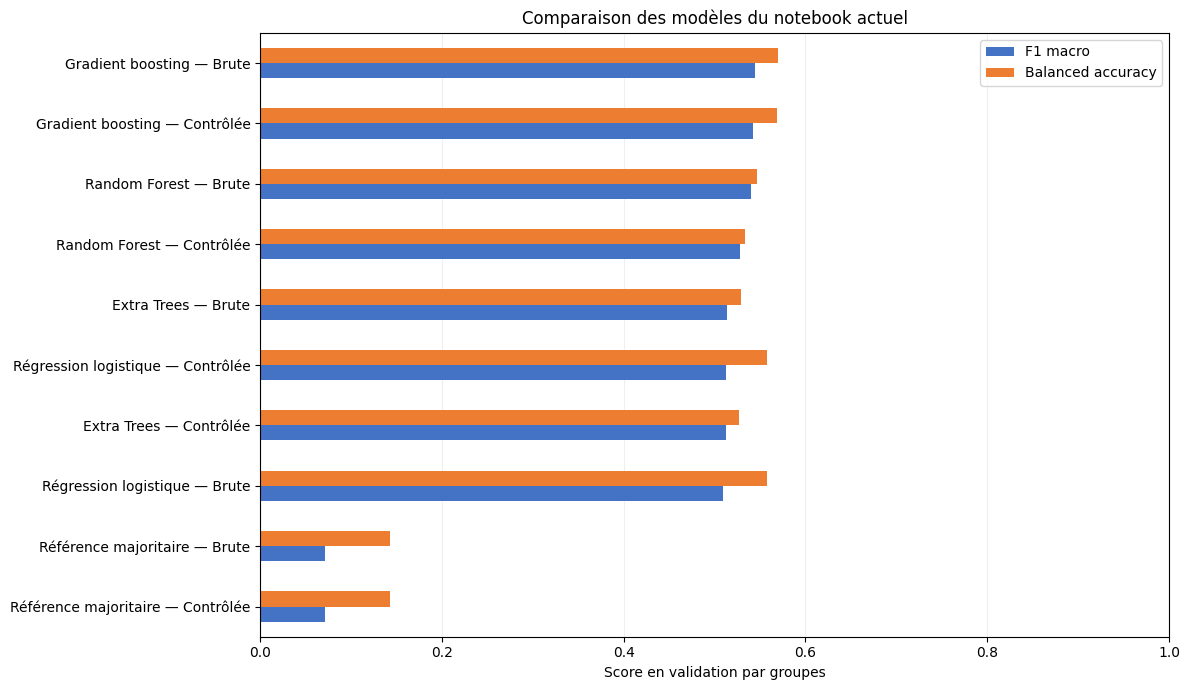


Durée totale : 4.9 minutes


In [11]:
import time
import warnings
import sklearn

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier
)
from sklearn.metrics import accuracy_score, f1_score, recall_score
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits


#### 1. Définir uniquement les données de ce notebook
donnees_actuelles = {
    "Brute": X_app_brut,
    "Contrôlée": X_app_controle
}

index_actuel = X_app_brut.index
y_actuel = y_app.loc[index_actuel].astype(str)
groupes_actuels = groupes_app.loc[index_actuel]
sources_actuelles = df_app.loc[index_actuel, "source_dpe"].astype(str)

for variante, table in donnees_actuelles.items():
    if not table.index.equals(index_actuel):
        raise ValueError(f"Ordre des lignes différent : {variante}")

    if list(table.columns) != list(X_app_brut.columns):
        raise ValueError(f"Variables différentes : {variante}")

print("Version scikit-learn :", sklearn.__version__)
print("Logements comparés :", len(y_actuel))
print("Variables candidates :", X_app_brut.shape[1])


#### 2. Définir une préparation commune aux modèles
preparation_actuelle = ColumnTransformer([
    (
        "numerique",
        Pipeline([
            (
                "imputation",
                SimpleImputer(
                    strategy="median",
                    add_indicator=True,
                    keep_empty_features=True
                )
            ),
            ("standardisation", StandardScaler())
        ]),
        numeriques_modele
    ),
    (
        "categoriel",
        Pipeline([
            (
                "imputation",
                SimpleImputer(
                    strategy="constant",
                    fill_value="__manquant__",
                    keep_empty_features=True
                )
            ),
            (
                "encodage",
                OneHotEncoder(
                    handle_unknown="ignore",
                    min_frequency=10,
                    sparse_output=False
                )
            )
        ]),
        categorielles_modele
    )
])


#### 3. Définir les modèles avec des réglages de départ
modeles_actuels = {
    "Référence majoritaire": DummyClassifier(
        strategy="most_frequent"
    ),

    "Régression logistique": LogisticRegression(
        C=1.0,
        class_weight="balanced",
        solver="lbfgs",
        max_iter=2000,
        tol=1e-3
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=2,
        max_features="sqrt",
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=42
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200,
        min_samples_leaf=2,
        max_features="sqrt",
        class_weight="balanced",
        n_jobs=-1,
        random_state=42
    ),

    "Gradient boosting": HistGradientBoostingClassifier(
        max_iter=150,
        max_leaf_nodes=15,
        learning_rate=0.08,
        l2_regularization=1.0,
        class_weight="balanced",
        early_stopping=False,
        random_state=42
    )
}


#### 4. Créer les mêmes quatre plis pour toutes les comparaisons
validation_actuelle = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

plis_actuels = list(
    validation_actuelle.split(
        X_app_brut,
        y_actuel,
        groups=groupes_actuels
    )
)

print("\nPlis de validation :")

for numero, (idx_train, idx_validation) in enumerate(plis_actuels, 1):
    groupes_partages = (
        set(groupes_actuels.iloc[idx_train])
        & set(groupes_actuels.iloc[idx_validation])
    )

    print(
        f"Pli {numero} : {len(idx_train)} apprentissage, "
        f"{len(idx_validation)} validation, "
        f"{len(groupes_partages)} groupe partagé"
    )

    if groupes_partages:
        raise ValueError("Un groupe apparaît dans les deux parties du pli.")


#### 5. Calculer les scores directement à partir des prédictions
def calculer_scores_actuels(vrais, predits):
    vrais = np.asarray(vrais, dtype=str)
    predits = np.asarray(predits, dtype=str)

    classes_presentes = sorted(np.unique(vrais))

    return {
        "accuracy": accuracy_score(vrais, predits),
        "f1_macro": f1_score(
            vrais,
            predits,
            labels=classes_presentes,
            average="macro",
            zero_division=0
        ),
        "balanced_accuracy": recall_score(
            vrais,
            predits,
            labels=classes_presentes,
            average="macro",
            zero_division=0
        )
    }


#### 6. Initialiser de nouveaux résultats pour cette comparaison
predictions_oof_actuelles = {
    (variante, nom): pd.Series(
        index=index_actuel,
        dtype="object"
    )
    for variante in donnees_actuelles
    for nom in modeles_actuels
}

lignes_plis_actuels = []
entrainement_numero = 0

total_entrainements = (
    len(plis_actuels)
    * len(donnees_actuelles)
    * len(modeles_actuels)
)

debut_comparaison = time.perf_counter()


#### 7. Apprendre la préparation uniquement sur l'apprentissage du pli
#### La préparation est calculée une fois par variante et par pli
with threadpool_limits(limits=2):

    for numero_pli, (idx_train, idx_validation) in enumerate(plis_actuels, 1):

        y_train = y_actuel.iloc[idx_train].to_numpy(dtype=str)
        y_validation = y_actuel.iloc[idx_validation].to_numpy(dtype=str)

        index_validation = index_actuel[idx_validation]

        for variante, table in donnees_actuelles.items():

            print(
                f"\nPréparation — pli {numero_pli}/4 — {variante}",
                flush=True
            )

            preparateur_pli = clone(preparation_actuelle)

            matrice_train = preparateur_pli.fit_transform(
                table.iloc[idx_train]
            )

            matrice_validation = preparateur_pli.transform(
                table.iloc[idx_validation]
            )

            #### Entraîner chaque modèle sur exactement les mêmes entrées
            for nom, prototype in modeles_actuels.items():
                entrainement_numero += 1

                print(
                    f"[{entrainement_numero}/{total_entrainements}] "
                    f"{nom} — {variante} — pli {numero_pli}/4...",
                    flush=True
                )

                modele_pli = clone(prototype)
                debut_modele = time.perf_counter()

                with warnings.catch_warnings(record=True) as alertes:
                    warnings.simplefilter("always", ConvergenceWarning)

                    modele_pli.fit(matrice_train, y_train)

                    predictions = np.asarray(
                        modele_pli.predict(matrice_validation),
                        dtype=str
                    )

                duree = time.perf_counter() - debut_modele

                nb_convergence = sum(
                    isinstance(alerte.message, ConvergenceWarning)
                    for alerte in alertes
                )

                for alerte in alertes:
                    if not isinstance(alerte.message, ConvergenceWarning):
                        print("Avertissement :", str(alerte.message)[:300])

                predictions_oof_actuelles[
                    (variante, nom)
                ].loc[index_validation] = predictions

                scores = calculer_scores_actuels(
                    y_validation,
                    predictions
                )

                lignes_plis_actuels.append({
                    "variante": variante,
                    "modele": nom,
                    "pli": numero_pli,
                    **scores,
                    "duree_secondes": duree,
                    "alertes_convergence": nb_convergence
                })

                print(
                    f"Terminé en {duree:.1f} s — "
                    f"F1 macro : {scores['f1_macro']:.3f} — "
                    f"alertes de convergence : {nb_convergence}",
                    flush=True
                )


#### 8. Regrouper les prédictions hors pli
resultats_plis_actuels = pd.DataFrame(lignes_plis_actuels)

lignes_globales = []
lignes_sources = []

for (variante, nom), predictions in predictions_oof_actuelles.items():

    if predictions.isna().any():
        raise ValueError(f"Prédictions incomplètes : {nom}, {variante}")

    scores = calculer_scores_actuels(y_actuel, predictions)

    details = resultats_plis_actuels.loc[
        resultats_plis_actuels["variante"].eq(variante)
        & resultats_plis_actuels["modele"].eq(nom)
    ]

    lignes_globales.append({
        "modele": nom,
        "variante": variante,
        **scores,
        "f1_moyen_plis": details["f1_macro"].mean(),
        "ecart_type_f1_plis": details["f1_macro"].std(ddof=0),
        "duree_modeles_secondes": details["duree_secondes"].sum(),
        "alertes_convergence": details["alertes_convergence"].sum()
    })

    #### Examiner également les résultats par source
    for source in ["existant", "neuf"]:
        masque = sources_actuelles.eq(source)

        scores_source = calculer_scores_actuels(
            y_actuel.loc[masque],
            predictions.loc[masque]
        )

        lignes_sources.append({
            "modele": nom,
            "variante": variante,
            "source": source,
            "logements": int(masque.sum()),
            "classes_evaluees": ", ".join(
                sorted(y_actuel.loc[masque].unique())
            ),
            **scores_source
        })


#### 9. Afficher le classement de cette première comparaison
comparaison_actuelle = (
    pd.DataFrame(lignes_globales)
    .sort_values("f1_macro", ascending=False)
    .reset_index(drop=True)
)

comparaison_sources_actuelle = (
    pd.DataFrame(lignes_sources)
    .sort_values(
        ["source", "f1_macro"],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

print("\nCOMPARAISON GLOBALE — PRÉDICTIONS HORS PLI")
display(comparaison_actuelle.round(3))

print("\nRÉSULTATS PAR SOURCE")
display(comparaison_sources_actuelle.round(3))


#### 10. Créer le graphique de comparaison
graphique_actuel = comparaison_actuelle.copy()

graphique_actuel["configuration"] = (
    graphique_actuel["modele"]
    + " — "
    + graphique_actuel["variante"]
)

ax = (
    graphique_actuel
    .set_index("configuration")[
        ["f1_macro", "balanced_accuracy"]
    ]
    .iloc[::-1]
    .plot(
        kind="barh",
        figsize=(12, 7),
        color=["#4472C4", "#ED7D31"]
    )
)

ax.set_title("Comparaison des modèles du notebook actuel")
ax.set_xlabel("Score en validation par groupes")
ax.set_ylabel("")
ax.set_xlim(0, 1)
ax.legend(["F1 macro", "Balanced accuracy"])
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(
    str(DOSSIER_SORTIES / 'comparaison_modeles_notebook_actuel.png'),
    dpi=150,
    bbox_inches="tight"
)
plt.show()


#### 11. Conserver les résultats de cette comparaison
comparaison_actuelle.to_csv(
    str(DOSSIER_SORTIES / 'comparaison_modeles_notebook_actuel.csv'),
    index=False
)

comparaison_sources_actuelle.to_csv(
    str(DOSSIER_SORTIES / 'comparaison_sources_notebook_actuel.csv'),
    index=False
)

resultats_plis_actuels.to_csv(
    str(DOSSIER_SORTIES / 'resultats_plis_notebook_actuel.csv'),
    index=False
)

print(
    "\nDurée totale :",
    round((time.perf_counter() - debut_comparaison) / 60, 1),
    "minutes"
)


--- EXISTANT : résultats hors pli ---


,modele,source,classe,precision,rappel,f1,effectif
0,Gradient boosting,existant,A,0.638,0.352,0.453,145
1,Random Forest,existant,A,0.780,0.221,0.344,145
2,Gradient boosting,existant,B,0.456,0.458,0.457,487
3,Random Forest,existant,B,0.509,0.287,0.367,487
4,Gradient boosting,existant,C,0.774,0.584,0.666,2854
5,Random Forest,existant,C,0.720,0.650,0.683,2854
6,Gradient boosting,existant,D,0.526,0.615,0.567,2368
7,Random Forest,existant,D,0.511,0.635,0.566,2368
8,Gradient boosting,existant,E,0.420,0.447,0.433,1222
9,Random Forest,existant,E,0.433,0.418,0.425,1222



--- NEUF : résultats hors pli ---


,modele,source,classe,precision,rappel,f1,effectif
0,Gradient boosting,neuf,A,0.880,0.909,0.895,3845
1,Random Forest,neuf,A,0.871,0.907,0.889,3845
2,Gradient boosting,neuf,B,0.435,0.539,0.481,1715
3,Random Forest,neuf,B,0.488,0.436,0.460,1715
4,Gradient boosting,neuf,C,0.719,0.552,0.625,2303
5,Random Forest,neuf,C,0.711,0.720,0.715,2303
6,Gradient boosting,neuf,D,0.000,0.000,0.000,5
7,Random Forest,neuf,D,0.000,0.000,0.000,5
8,Gradient boosting,neuf,F,0.000,0.000,0.000,1
9,Random Forest,neuf,F,0.000,0.000,0.000,1


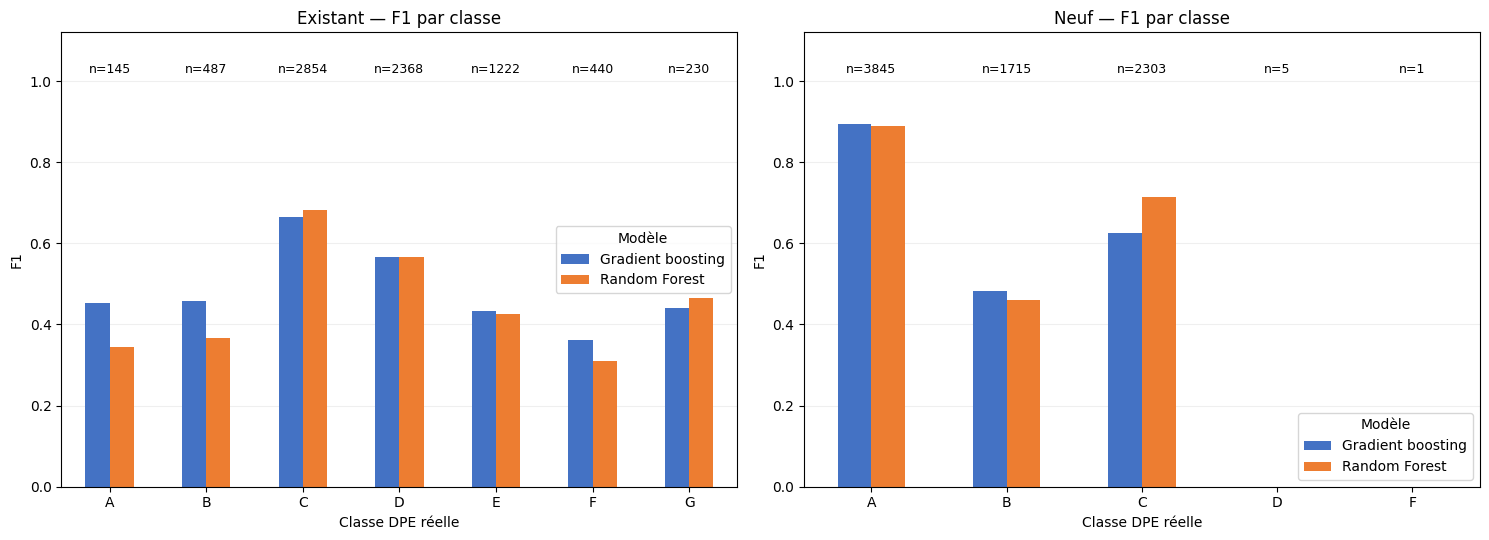

In [12]:
from sklearn.metrics import classification_report

#### 1. Examiner les deux meilleurs candidats sur les données brutes
candidats_diagnostic = [
    "Gradient boosting",
    "Random Forest"
]

rapports_sources_actuels = {}
lignes_diagnostic = []

#### 2. Calculer les résultats par classe et par source
for nom_modele in candidats_diagnostic:

    predictions = predictions_oof_actuelles[
        ("Brute", nom_modele)
    ]

    for source in ["existant", "neuf"]:

        masque = sources_actuelles.eq(source)

        vrais = y_actuel.loc[masque].to_numpy(dtype=str)
        predits = predictions.loc[masque].to_numpy(dtype=str)

        classes_presentes = sorted(np.unique(vrais))

        rapport = pd.DataFrame(
            classification_report(
                vrais,
                predits,
                labels=classes_presentes,
                output_dict=True,
                zero_division=0
            )
        ).T.reindex(classes_presentes)

        rapport = rapport[
            ["precision", "recall", "f1-score", "support"]
        ].copy()

        rapport["support"] = rapport["support"].astype(int)

        rapports_sources_actuels[(nom_modele, source)] = rapport

        for classe, ligne in rapport.iterrows():
            lignes_diagnostic.append({
                "modele": nom_modele,
                "source": source,
                "classe": classe,
                "precision": ligne["precision"],
                "rappel": ligne["recall"],
                "f1": ligne["f1-score"],
                "effectif": int(ligne["support"])
            })

#### 3. Afficher un tableau lisible pour chaque source
diagnostic_classes_actuel = pd.DataFrame(lignes_diagnostic)

for source in ["existant", "neuf"]:
    print(f"\n--- {source.upper()} : résultats hors pli ---")

    display(
        diagnostic_classes_actuel.loc[
            diagnostic_classes_actuel["source"].eq(source)
        ]
        .sort_values(["classe", "modele"])
        .reset_index(drop=True)
        .round(3)
    )

#### 4. Comparer visuellement les F1 par classe
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

for ax, source in zip(axes, ["existant", "neuf"]):

    extrait = diagnostic_classes_actuel.loc[
        diagnostic_classes_actuel["source"].eq(source)
    ]

    tableau_f1 = extrait.pivot(
        index="classe",
        columns="modele",
        values="f1"
    ).reindex(columns=candidats_diagnostic)

    tableau_f1.plot(
        kind="bar",
        ax=ax,
        color=["#4472C4", "#ED7D31"],
        rot=0
    )

    effectifs = (
        extrait.drop_duplicates("classe")
        .set_index("classe")["effectif"]
    )

    for position, classe in enumerate(tableau_f1.index):
        ax.text(
            position,
            1.02,
            f"n={effectifs.loc[classe]}",
            ha="center",
            fontsize=9
        )

    ax.set_title(f"{source.capitalize()} — F1 par classe")
    ax.set_xlabel("Classe DPE réelle")
    ax.set_ylabel("F1")
    ax.set_ylim(0, 1.12)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.legend(title="Modèle")

plt.tight_layout()
plt.savefig(
    str(DOSSIER_SORTIES / 'diagnostic_classes_notebook_actuel.png'),
    dpi=150,
    bbox_inches="tight"
)
plt.show()

#### 5. Enregistrer les résultats pour le rapport
diagnostic_classes_actuel.to_csv(
    str(DOSSIER_SORTIES / 'diagnostic_classes_notebook_actuel.csv'),
    index=False
)

COMPARAISON GLOBALE — prédictions hors pli


,strategie,accuracy,f1_macro,balanced_accuracy,f1_moyen_plis,ecart_type_f1_plis
0,Combinaison par source,0.650,0.547,0.568,0.546,0.019
1,Gradient boosting global,0.637,0.544,0.569,0.543,0.012
2,Random Forest global,0.653,0.540,0.547,0.540,0.012



RÉSULTATS PAR SOURCE


,strategie,source,accuracy,f1_macro,balanced_accuracy
0,Gradient boosting global,existant,0.550,0.483,0.486
1,Gradient boosting global,neuf,0.723,0.400,0.400
2,Random Forest global,existant,0.555,0.452,0.432
3,Random Forest global,neuf,0.749,0.413,0.413
4,Combinaison par source,existant,0.550,0.483,0.486
5,Combinaison par source,neuf,0.749,0.413,0.413


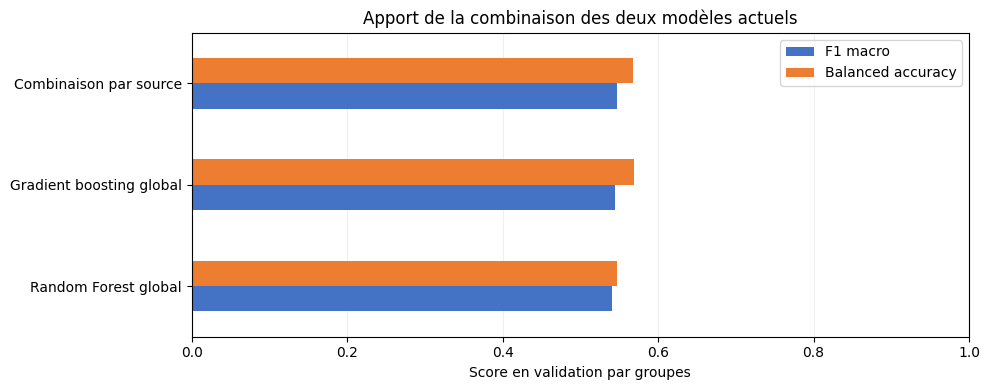

In [13]:
#### 1. Reprendre les prédictions hors pli du notebook actuel
predictions_gb_actuelles = predictions_oof_actuelles[
    ("Brute", "Gradient boosting")
].copy()

predictions_rf_actuelles = predictions_oof_actuelles[
    ("Brute", "Random Forest")
].copy()

#### 2. Construire la combinaison proposée
predictions_combinaison_actuelle = predictions_gb_actuelles.copy()

masque_neuf = sources_actuelles.eq("neuf")

predictions_combinaison_actuelle.loc[masque_neuf] = (
    predictions_rf_actuelles.loc[masque_neuf]
)

#### Conserver la règle exacte pour la suite
regle_combinaison_actuelle = {
    "existant": "Gradient boosting",
    "neuf": "Random Forest"
}

#### 3. Comparer les trois stratégies avec les mêmes observations
predictions_strategies_actuelles = {
    "Gradient boosting global": predictions_gb_actuelles,
    "Random Forest global": predictions_rf_actuelles,
    "Combinaison par source": predictions_combinaison_actuelle
}

bilan_strategies = []
bilan_sources = []

for nom, predictions in predictions_strategies_actuelles.items():

    if not predictions.index.equals(y_actuel.index):
        raise ValueError(f"Alignement incorrect : {nom}")

    if predictions.isna().any():
        raise ValueError(f"Prédictions manquantes : {nom}")

    scores = calculer_scores_actuels(y_actuel, predictions)

    #### Examiner aussi la variation du F1 entre les quatre plis
    f1_plis = []

    for _, idx_validation in plis_actuels:
        scores_pli = calculer_scores_actuels(
            y_actuel.iloc[idx_validation],
            predictions.iloc[idx_validation]
        )
        f1_plis.append(scores_pli["f1_macro"])

    bilan_strategies.append({
        "strategie": nom,
        **scores,
        "f1_moyen_plis": np.mean(f1_plis),
        "ecart_type_f1_plis": np.std(f1_plis, ddof=0)
    })

    for source in ["existant", "neuf"]:
        masque = sources_actuelles.eq(source)

        scores_source = calculer_scores_actuels(
            y_actuel.loc[masque],
            predictions.loc[masque]
        )

        bilan_sources.append({
            "strategie": nom,
            "source": source,
            **scores_source
        })

comparaison_strategies_actuelle = (
    pd.DataFrame(bilan_strategies)
    .sort_values("f1_macro", ascending=False)
    .reset_index(drop=True)
)

comparaison_strategies_sources_actuelle = pd.DataFrame(bilan_sources)

print("COMPARAISON GLOBALE — prédictions hors pli")
display(comparaison_strategies_actuelle.round(3))

print("\nRÉSULTATS PAR SOURCE")
display(comparaison_strategies_sources_actuelle.round(3))

#### 4. Visualiser le résultat global
ax = (
    comparaison_strategies_actuelle
    .set_index("strategie")[["f1_macro", "balanced_accuracy"]]
    .iloc[::-1]
    .plot(
        kind="barh",
        figsize=(10, 4),
        color=["#4472C4", "#ED7D31"]
    )
)

ax.set_title("Apport de la combinaison des deux modèles actuels")
ax.set_xlabel("Score en validation par groupes")
ax.set_ylabel("")
ax.set_xlim(0, 1)
ax.legend(["F1 macro", "Balanced accuracy"])
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(
    str(DOSSIER_SORTIES / 'comparaison_combinaison_notebook_actuel.png'),
    dpi=150,
    bbox_inches="tight"
)
plt.show()

#### 5. Conserver cette comparaison
comparaison_strategies_actuelle.to_csv(
    str(DOSSIER_SORTIES / 'comparaison_combinaison_notebook_actuel.csv'),
    index=False
)


Préparation du pli 1/4...
[1/16] GB — 31 feuilles — pli 1/4...
Terminé en 35.7 s — F1 macro : 0.551
[2/16] GB — sans pondération — pli 1/4...
Terminé en 36.8 s — F1 macro : 0.521
[3/16] RF — davantage de variables — pli 1/4...
Terminé en 22.1 s — F1 macro : 0.539
[4/16] RF — sans pondération — pli 1/4...
Terminé en 3.4 s — F1 macro : 0.489

Préparation du pli 2/4...
[5/16] GB — 31 feuilles — pli 2/4...
Terminé en 52.7 s — F1 macro : 0.567
[6/16] GB — sans pondération — pli 2/4...
Terminé en 28.1 s — F1 macro : 0.556
[7/16] RF — davantage de variables — pli 2/4...
Terminé en 13.7 s — F1 macro : 0.541
[8/16] RF — sans pondération — pli 2/4...
Terminé en 4.6 s — F1 macro : 0.516

Préparation du pli 3/4...
[9/16] GB — 31 feuilles — pli 3/4...
Terminé en 31.4 s — F1 macro : 0.548
[10/16] GB — sans pondération — pli 3/4...
Terminé en 22.7 s — F1 macro : 0.521
[11/16] RF — davantage de variables — pli 3/4...
Terminé en 13.5 s — F1 macro : 0.525
[12/16] RF — sans pondération — pli 3/4...
Term

,configuration,nombre_modeles,accuracy,f1_macro,balanced_accuracy,f1_moyen_plis,ecart_type_f1_plis
0,GB — 31 feuilles,1,0.645,0.548,0.557,0.548,0.014
1,Combinaison actuelle,2,0.650,0.547,0.568,0.546,0.019
2,GB — initial,1,0.637,0.544,0.569,0.543,0.012
3,RF — initial,1,0.653,0.540,0.547,0.540,0.012
4,RF — davantage de variables,1,0.648,0.531,0.531,0.530,0.011
5,GB — sans pondération,1,0.661,0.531,0.521,0.530,0.015
6,RF — sans pondération,1,0.662,0.492,0.473,0.491,0.017



RÉSULTATS PAR SOURCE


,configuration,source,accuracy,f1_macro,balanced_accuracy
0,GB — 31 feuilles,existant,0.571,0.492,0.482
1,GB — initial,existant,0.550,0.483,0.486
2,Combinaison actuelle,existant,0.550,0.483,0.486
3,GB — sans pondération,existant,0.579,0.482,0.453
4,RF — davantage de variables,existant,0.565,0.461,0.439
5,RF — initial,existant,0.555,0.452,0.432
6,RF — sans pondération,existant,0.567,0.418,0.375
7,RF — initial,neuf,0.749,0.413,0.413
8,Combinaison actuelle,neuf,0.749,0.413,0.413
9,GB — initial,neuf,0.723,0.400,0.400


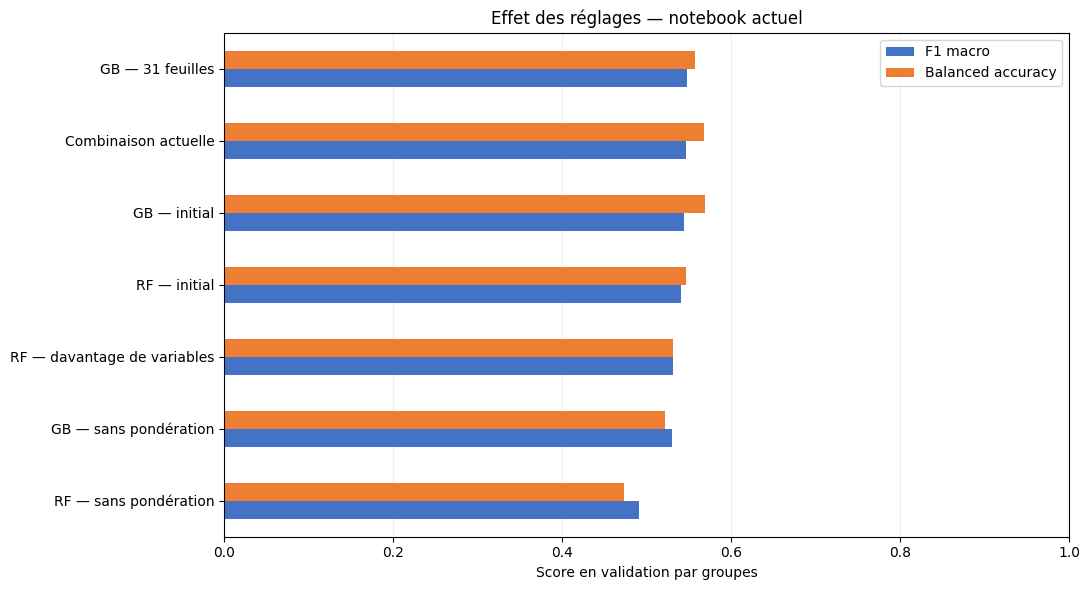

In [14]:
#### 1. Définir les quatre nouveaux réglages
nouveaux_reglages_actuels = {
    "GB — 31 feuilles": clone(
        modeles_actuels["Gradient boosting"]
    ).set_params(max_leaf_nodes=31),

    "GB — sans pondération": clone(
        modeles_actuels["Gradient boosting"]
    ).set_params(class_weight=None),

    "RF — davantage de variables": clone(
        modeles_actuels["Random Forest"]
    ).set_params(max_features=0.5),

    "RF — sans pondération": clone(
        modeles_actuels["Random Forest"]
    ).set_params(class_weight=None)
}

#### 2. Conserver les configurations exactes pour la suite
configurations_reglages_actuelles = {
    "GB — initial": clone(modeles_actuels["Gradient boosting"]),
    "RF — initial": clone(modeles_actuels["Random Forest"]),
    **nouveaux_reglages_actuels
}

#### 3. Reprendre uniquement les résultats initiaux de ce notebook
predictions_reglages_actuelles = {
    "GB — initial": predictions_oof_actuelles[
        ("Brute", "Gradient boosting")
    ].copy(),

    "RF — initial": predictions_oof_actuelles[
        ("Brute", "Random Forest")
    ].copy()
}

for nom in nouveaux_reglages_actuels:
    predictions_reglages_actuelles[nom] = pd.Series(
        index=index_actuel,
        dtype="object"
    )

details_nouveaux_reglages = []
numero_entrainement = 0

total_entrainements = (
    len(plis_actuels) * len(nouveaux_reglages_actuels)
)


#### 4. Évaluer les réglages sur les mêmes plis
with threadpool_limits(limits=2):

    for numero_pli, (idx_train, idx_validation) in enumerate(plis_actuels, 1):

        print(f"\nPréparation du pli {numero_pli}/4...", flush=True)

        preparateur_pli = clone(preparation_actuelle)

        matrice_train = preparateur_pli.fit_transform(
            X_app_brut.iloc[idx_train]
        )

        matrice_validation = preparateur_pli.transform(
            X_app_brut.iloc[idx_validation]
        )

        y_train = y_actuel.iloc[idx_train].to_numpy(dtype=str)
        y_validation = y_actuel.iloc[idx_validation].to_numpy(dtype=str)
        index_validation = index_actuel[idx_validation]

        for nom, prototype in nouveaux_reglages_actuels.items():
            numero_entrainement += 1

            print(
                f"[{numero_entrainement}/{total_entrainements}] "
                f"{nom} — pli {numero_pli}/4...",
                flush=True
            )

            debut = time.perf_counter()
            modele_pli = clone(prototype)

            modele_pli.fit(matrice_train, y_train)

            predictions = np.asarray(
                modele_pli.predict(matrice_validation),
                dtype=str
            )

            duree = time.perf_counter() - debut

            predictions_reglages_actuelles[nom].loc[
                index_validation
            ] = predictions

            scores = calculer_scores_actuels(
                y_validation,
                predictions
            )

            details_nouveaux_reglages.append({
                "configuration": nom,
                "pli": numero_pli,
                **scores,
                "duree_secondes": duree
            })

            print(
                f"Terminé en {duree:.1f} s — "
                f"F1 macro : {scores['f1_macro']:.3f}",
                flush=True
            )


#### 5. Ajouter la combinaison déjà évaluée comme point de comparaison
predictions_reglages_actuelles["Combinaison actuelle"] = (
    predictions_combinaison_actuelle.copy()
)


#### 6. Comparer les résultats regroupés des quatre plis
bilan_reglages = []
bilan_sources_reglages = []

for nom, predictions in predictions_reglages_actuelles.items():

    if not predictions.index.equals(y_actuel.index):
        raise ValueError(f"Alignement incorrect : {nom}")

    if predictions.isna().any():
        raise ValueError(f"Prédictions incomplètes : {nom}")

    scores = calculer_scores_actuels(y_actuel, predictions)

    f1_plis = [
        calculer_scores_actuels(
            y_actuel.iloc[idx_validation],
            predictions.iloc[idx_validation]
        )["f1_macro"]
        for _, idx_validation in plis_actuels
    ]

    bilan_reglages.append({
        "configuration": nom,
        "nombre_modeles": 2 if nom == "Combinaison actuelle" else 1,
        **scores,
        "f1_moyen_plis": np.mean(f1_plis),
        "ecart_type_f1_plis": np.std(f1_plis, ddof=0)
    })

    for source in ["existant", "neuf"]:
        masque = sources_actuelles.eq(source)

        bilan_sources_reglages.append({
            "configuration": nom,
            "source": source,
            **calculer_scores_actuels(
                y_actuel.loc[masque],
                predictions.loc[masque]
            )
        })

comparaison_reglages_actuelle = (
    pd.DataFrame(bilan_reglages)
    .sort_values("f1_macro", ascending=False)
    .reset_index(drop=True)
)

comparaison_sources_reglages_actuelle = pd.DataFrame(
    bilan_sources_reglages
)

print("\nCOMPARAISON DES RÉGLAGES — prédictions hors pli")
display(comparaison_reglages_actuelle.round(3))

print("\nRÉSULTATS PAR SOURCE")
display(
    comparaison_sources_reglages_actuelle
    .sort_values(["source", "f1_macro"], ascending=[True, False])
    .reset_index(drop=True)
    .round(3)
)


#### 7. Visualiser la comparaison
ax = (
    comparaison_reglages_actuelle
    .set_index("configuration")[["f1_macro", "balanced_accuracy"]]
    .iloc[::-1]
    .plot(
        kind="barh",
        figsize=(11, 6),
        color=["#4472C4", "#ED7D31"]
    )
)

ax.set_title("Effet des réglages — notebook actuel")
ax.set_xlabel("Score en validation par groupes")
ax.set_ylabel("")
ax.set_xlim(0, 1)
ax.legend(["F1 macro", "Balanced accuracy"])
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(
    str(DOSSIER_SORTIES / 'comparaison_reglages_notebook_actuel.png'),
    dpi=150,
    bbox_inches="tight"
)
plt.show()


#### 8. Enregistrer les résultats
comparaison_reglages_actuelle.to_csv(
    str(DOSSIER_SORTIES / 'comparaison_reglages_notebook_actuel.csv'),
    index=False
)

comparaison_sources_reglages_actuelle.to_csv(
    str(DOSSIER_SORTIES / 'comparaison_sources_reglages_notebook_actuel.csv'),
    index=False
)

pd.DataFrame(details_nouveaux_reglages).to_csv(
    str(DOSSIER_SORTIES / 'details_nouveaux_reglages_notebook_actuel.csv'),
    index=False
)

Configuration retenue : GB — 31 feuilles
Apprentissage : (15615, 31)
Test final : (3891, 31)
Groupes partagés : 0

Entraînement du modèle retenu...
Entraînement et prédiction terminés en 38.8 secondes

RÉSULTATS SUR LE TEST FINAL


,modele,accuracy,f1_macro,balanced_accuracy,exact_ou_une_classe_ecart,ecart_moyen_classes,kappa_quadratique
0,GB — 31 feuilles,0.640,0.547,0.567,0.955,0.408,0.88
1,Référence majoritaire,0.349,0.074,0.143,0.636,1.072,0.00



RAPPORT GLOBAL PAR CLASSE


,precision,recall,f1-score,support
classe,,,,
A,0.865,0.899,0.881,959
B,0.422,0.517,0.465,540
C,0.750,0.567,0.646,1358
D,0.550,0.649,0.596,576
E,0.416,0.463,0.438,294
F,0.326,0.419,0.367,105
G,0.422,0.458,0.439,59



RÉSULTATS PAR SOURCE


,source,logements,classes_evaluees,accuracy,f1_macro,balanced_accuracy
0,existant,1935,"A, B, C, D, E, F, G",0.556,0.490,0.497
1,neuf,1956,"A, B, C",0.724,0.668,0.669


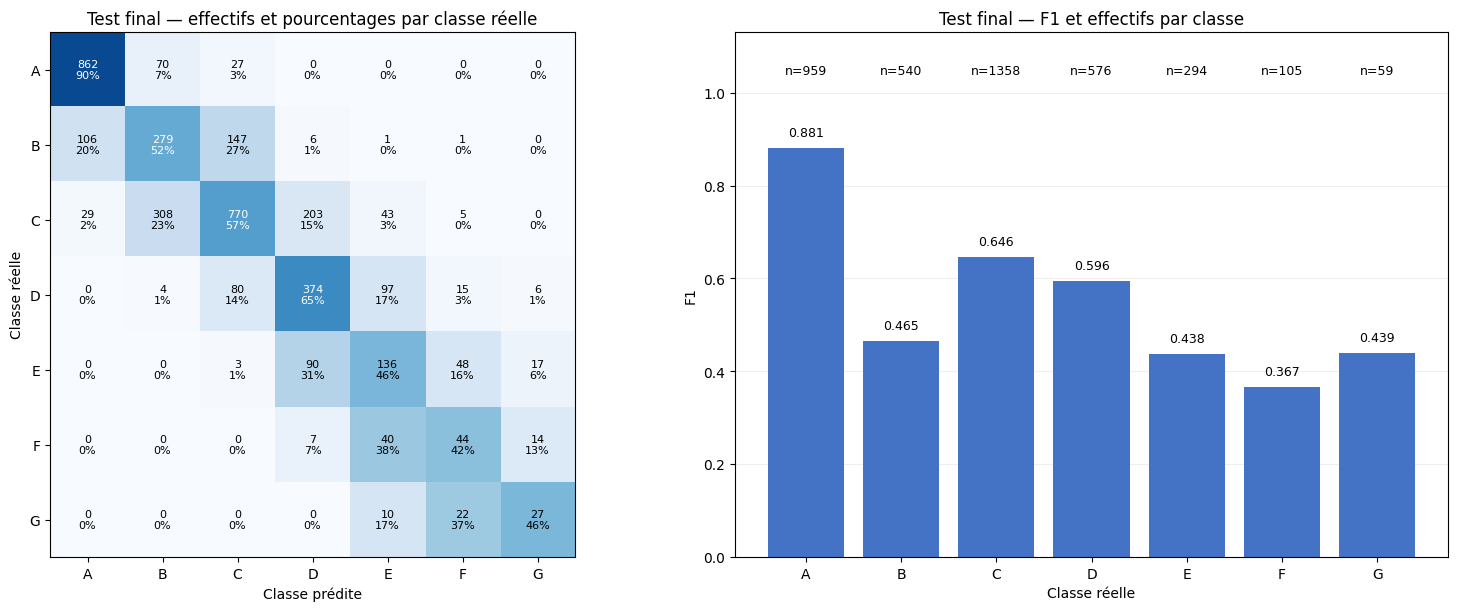

In [15]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    cohen_kappa_score
)

#### 1. Fixer la configuration choisie en validation
nom_retenu_actuel = "GB — 31 feuilles"

pipeline_retenu_actuel = Pipeline([
    ("preparation", clone(preparation_actuelle)),
    (
        "modele",
        clone(configurations_reglages_actuelles[nom_retenu_actuel])
    )
])

#### 2. Préparer les entrées du test avec la même fonction déterministe
#### Le modèle retenu utilise la variante brute
X_test_actuel = construire_variables(df_test)
y_test_actuel = df_test["etiquette_dpe"].astype(str)

if list(X_test_actuel.columns) != list(X_app_brut.columns):
    raise ValueError("Les variables du test diffèrent de l'apprentissage.")

if not X_test_actuel.index.equals(y_test_actuel.index):
    raise ValueError("Les entrées et les étiquettes du test sont désalignées.")

groupes_partages = set(groupes_app) & set(groupes_test)

if groupes_partages:
    raise ValueError("Des groupes sont partagés entre apprentissage et test.")

print("Configuration retenue :", nom_retenu_actuel)
print("Apprentissage :", X_app_brut.shape)
print("Test final :", X_test_actuel.shape)
print("Groupes partagés :", len(groupes_partages))


#### 3. Ajuster le pipeline uniquement sur les 15 615 logements d'apprentissage
print("\nEntraînement du modèle retenu...", flush=True)

debut = time.perf_counter()

with threadpool_limits(limits=2):
    pipeline_retenu_actuel.fit(
        X_app_brut,
        y_actuel.to_numpy(dtype=str)
    )

    predictions_test_actuelles = pd.Series(
        pipeline_retenu_actuel.predict(X_test_actuel),
        index=X_test_actuel.index,
        name="prediction"
    )

print(
    "Entraînement et prédiction terminés en",
    round(time.perf_counter() - debut, 1),
    "secondes"
)


#### 4. Calculer la référence majoritaire sur la même partition
reference_test_actuelle = clone(
    modeles_actuels["Référence majoritaire"]
)

reference_test_actuelle.fit(
    np.zeros((len(y_actuel), 1)),
    y_actuel.to_numpy(dtype=str)
)

predictions_reference_test_actuelles = reference_test_actuelle.predict(
    np.zeros((len(y_test_actuel), 1))
)


#### 5. Ajouter des métriques tenant compte de l'ordre A–G
ordre_classes_actuel = list("ABCDEFG")
positions_classes_actuelles = {
    classe: position
    for position, classe in enumerate(ordre_classes_actuel)
}

def metriques_completes_actuelles(vrais, predits):
    vrais = np.asarray(vrais, dtype=str)
    predits = np.asarray(predits, dtype=str)

    scores = calculer_scores_actuels(vrais, predits)

    positions_vraies = np.array([
        positions_classes_actuelles[classe] for classe in vrais
    ])

    positions_predites = np.array([
        positions_classes_actuelles[classe] for classe in predits
    ])

    ecarts = np.abs(positions_vraies - positions_predites)

    return {
        **scores,
        "exact_ou_une_classe_ecart": np.mean(ecarts <= 1),
        "ecart_moyen_classes": np.mean(ecarts),
        "kappa_quadratique": cohen_kappa_score(
            vrais,
            predits,
            labels=ordre_classes_actuel,
            weights="quadratic"
        )
    }


metriques_test_final_actuelles = pd.DataFrame([
    {
        "modele": nom_retenu_actuel,
        **metriques_completes_actuelles(
            y_test_actuel,
            predictions_test_actuelles
        )
    },
    {
        "modele": "Référence majoritaire",
        **metriques_completes_actuelles(
            y_test_actuel,
            predictions_reference_test_actuelles
        )
    }
])

print("\nRÉSULTATS SUR LE TEST FINAL")
display(metriques_test_final_actuelles.round(3))


#### 6. Examiner les performances globales par classe
rapport_test_classes_actuel = pd.DataFrame(
    classification_report(
        y_test_actuel.to_numpy(dtype=str),
        predictions_test_actuelles.to_numpy(dtype=str),
        labels=ordre_classes_actuel,
        output_dict=True,
        zero_division=0
    )
).T.reindex(ordre_classes_actuel)

rapport_test_classes_actuel = rapport_test_classes_actuel[
    ["precision", "recall", "f1-score", "support"]
].copy()

rapport_test_classes_actuel["support"] = (
    rapport_test_classes_actuel["support"].astype(int)
)

rapport_test_classes_actuel.index.name = "classe"

print("\nRAPPORT GLOBAL PAR CLASSE")
display(rapport_test_classes_actuel.round(3))


#### 7. Examiner les performances par source
sources_test_actuelles = df_test["source_dpe"].astype(str)
lignes_sources_test = []
rapports_test_sources_actuels = {}

for source in ["existant", "neuf"]:
    masque = sources_test_actuelles.eq(source)

    vrais = y_test_actuel.loc[masque]
    predits = predictions_test_actuelles.loc[masque]
    classes_presentes = sorted(vrais.unique())

    lignes_sources_test.append({
        "source": source,
        "logements": int(masque.sum()),
        "classes_evaluees": ", ".join(classes_presentes),
        **calculer_scores_actuels(vrais, predits)
    })

    rapports_test_sources_actuels[source] = pd.DataFrame(
        classification_report(
            vrais.to_numpy(dtype=str),
            predits.to_numpy(dtype=str),
            labels=classes_presentes,
            output_dict=True,
            zero_division=0
        )
    ).T.reindex(classes_presentes)

resultats_sources_test_actuels = pd.DataFrame(lignes_sources_test)

print("\nRÉSULTATS PAR SOURCE")
display(resultats_sources_test_actuels.round(3))


#### 8. Construire la matrice de confusion
matrice_test_actuelle = confusion_matrix(
    y_test_actuel.to_numpy(dtype=str),
    predictions_test_actuelles.to_numpy(dtype=str),
    labels=ordre_classes_actuel
)

effectifs_reels = matrice_test_actuelle.sum(axis=1, keepdims=True)

proportions_test_actuelles = np.divide(
    matrice_test_actuelle,
    effectifs_reels,
    out=np.zeros_like(matrice_test_actuelle, dtype=float),
    where=effectifs_reels != 0
)


#### 9. Visualiser les erreurs et les F1 par classe
fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 6),
    constrained_layout=True
)

axes[0].imshow(
    proportions_test_actuelles,
    cmap="Blues",
    vmin=0,
    vmax=1
)

for i in range(7):
    for j in range(7):
        axes[0].text(
            j, i,
            f"{matrice_test_actuelle[i, j]}\n"
            f"{proportions_test_actuelles[i, j]:.0%}",
            ha="center",
            va="center",
            fontsize=8,
            color=(
                "white"
                if proportions_test_actuelles[i, j] > 0.5
                else "black"
            )
        )

axes[0].set_xticks(range(7))
axes[0].set_yticks(range(7))
axes[0].set_xticklabels(ordre_classes_actuel)
axes[0].set_yticklabels(ordre_classes_actuel)
axes[0].set_xlabel("Classe prédite")
axes[0].set_ylabel("Classe réelle")
axes[0].set_title("Test final — effectifs et pourcentages par classe réelle")

positions = np.arange(7)
f1_classes = rapport_test_classes_actuel["f1-score"].to_numpy()

axes[1].bar(positions, f1_classes, color="#4472C4")

for position, classe in enumerate(ordre_classes_actuel):
    axes[1].text(
        position,
        f1_classes[position] + 0.025,
        f"{f1_classes[position]:.3f}",
        ha="center",
        fontsize=9
    )

    axes[1].text(
        position,
        1.04,
        f"n={rapport_test_classes_actuel.loc[classe, 'support']}",
        ha="center",
        fontsize=9
    )

axes[1].set_xticks(positions)
axes[1].set_xticklabels(ordre_classes_actuel)
axes[1].set_ylim(0, 1.13)
axes[1].set_xlabel("Classe réelle")
axes[1].set_ylabel("F1")
axes[1].set_title("Test final — F1 et effectifs par classe")
axes[1].grid(axis="y", alpha=0.2)
axes[1].set_axisbelow(True)

plt.savefig(
    str(DOSSIER_SORTIES / 'evaluation_test_final_notebook_actuel.png'),
    dpi=150,
    bbox_inches="tight"
)
plt.show()


#### 10. Enregistrer les résultats avant tout réentraînement final
metriques_test_final_actuelles.to_csv(
    str(DOSSIER_SORTIES / 'metriques_test_final_notebook_actuel.csv'),
    index=False
)

rapport_test_classes_actuel.to_csv(
    str(DOSSIER_SORTIES / 'rapport_classes_test_final_notebook_actuel.csv')
)

resultats_sources_test_actuels.to_csv(
    str(DOSSIER_SORTIES / 'metriques_sources_test_final_notebook_actuel.csv'),
    index=False
)

predictions_test_a_conserver = df_test[
    ["numero_dpe", "source_dpe", "etiquette_dpe"]
].copy()

predictions_test_a_conserver["groupe"] = groupes_test.loc[df_test.index]
predictions_test_a_conserver["prediction"] = predictions_test_actuelles

predictions_test_a_conserver.to_csv(
    str(DOSSIER_SORTIES / 'predictions_test_final_notebook_actuel.csv'),
    index=False
)


Importance — pli 1/4 : entraînement...
Pli 1/4 : permutations des variables...
Pli 1/4 terminé.

Importance — pli 2/4 : entraînement...
Pli 2/4 : permutations des variables...
Pli 2/4 terminé.

Importance — pli 3/4 : entraînement...
Pli 3/4 : permutations des variables...
Pli 3/4 terminé.

Importance — pli 4/4 : entraînement...
Pli 4/4 : permutations des variables...
Pli 4/4 terminé.

IMPORTANCE DES VARIABLES — validation par groupes


,baisse_f1_moyenne,dispersion
variable,,
ubat_w_par_m2_k,0.1423,0.0156
source_dpe,0.0930,0.0131
type_energie_n1,0.0814,0.0089
qualite_isolation_murs,0.0354,0.0094
type_energie_principale_chauffage,0.0255,0.0103
zone_climatique,0.0247,0.0100
qualite_isolation_plancher_haut_comble_perdu,0.0221,0.0106
surface_habitable_logement,0.0204,0.0113
type_generateur_chauffage_principal,0.0202,0.0079


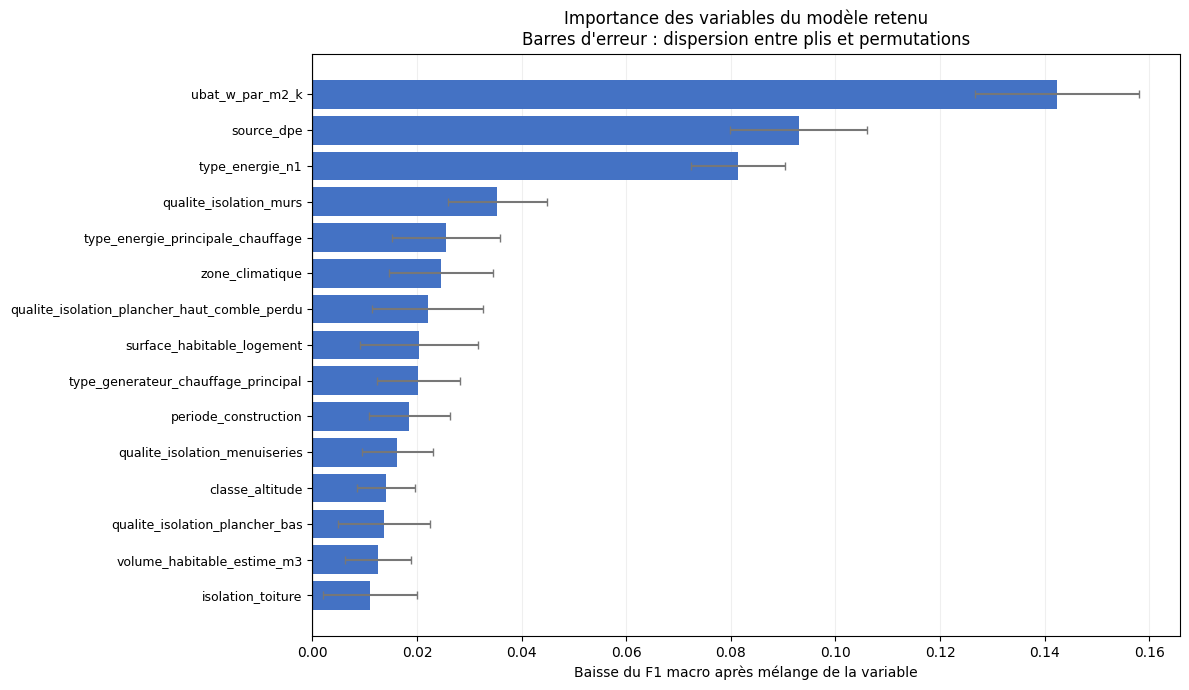

In [16]:
from sklearn.inspection import permutation_importance

#### 1. Définir directement le score pour éviter le problème pos_label=1
def score_importance_actuel(modele, entrees, vrais):
    predictions = modele.predict(entrees)

    return f1_score(
        np.asarray(vrais, dtype=str),
        np.asarray(predictions, dtype=str),
        labels=list("ABCDEFG"),
        average="macro",
        zero_division=0
    )


#### 2. Calculer les importances sur les validations des quatre plis
lignes_importance_actuelle = []

with threadpool_limits(limits=2):

    for numero_pli, (idx_train, idx_validation) in enumerate(plis_actuels, 1):

        print(
            f"\nImportance — pli {numero_pli}/4 : entraînement...",
            flush=True
        )

        #### Le clonage réinitialise le pipeline et son prétraitement
        pipeline_pli = clone(pipeline_retenu_actuel)

        pipeline_pli.fit(
            X_app_brut.iloc[idx_train],
            y_actuel.iloc[idx_train].to_numpy(dtype=str)
        )

        print(
            f"Pli {numero_pli}/4 : permutations des variables...",
            flush=True
        )

        resultat_importance = permutation_importance(
            estimator=pipeline_pli,
            X=X_app_brut.iloc[idx_validation],
            y=y_actuel.iloc[idx_validation].to_numpy(dtype=str),
            scoring=score_importance_actuel,
            n_repeats=3,
            random_state=42 + numero_pli,
            n_jobs=1
        )

        for position, variable in enumerate(X_app_brut.columns):
            for repetition, baisse in enumerate(
                resultat_importance.importances[position], 1
            ):
                lignes_importance_actuelle.append({
                    "pli": numero_pli,
                    "variable": variable,
                    "repetition": repetition,
                    "baisse_f1": float(baisse)
                })

        print(f"Pli {numero_pli}/4 terminé.", flush=True)


#### 3. Résumer les résultats des plis et des permutations
details_importance_actuelle = pd.DataFrame(
    lignes_importance_actuelle
)

importance_variables_actuelles = (
    details_importance_actuelle
    .groupby("variable")["baisse_f1"]
    .agg(["mean", "std"])
    .rename(columns={
        "mean": "baisse_f1_moyenne",
        "std": "dispersion"
    })
    .sort_values("baisse_f1_moyenne", ascending=False)
)

print("\nIMPORTANCE DES VARIABLES — validation par groupes")
display(importance_variables_actuelles.round(4))


#### 4. Visualiser les 15 premières variables
a_afficher = importance_variables_actuelles.head(15).iloc[::-1]

fig, ax = plt.subplots(figsize=(12, 7))

ax.barh(
    a_afficher.index,
    a_afficher["baisse_f1_moyenne"],
    xerr=a_afficher["dispersion"],
    color="#4472C4",
    ecolor="#777777",
    capsize=3
)

ax.axvline(0, color="black", linewidth=0.8)

ax.set_title(
    "Importance des variables du modèle retenu\n"
    "Barres d'erreur : dispersion entre plis et permutations"
)

ax.set_xlabel("Baisse du F1 macro après mélange de la variable")
ax.set_ylabel("")
ax.tick_params(axis="y", labelsize=9)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(
    str(DOSSIER_SORTIES / 'importance_variables_notebook_actuel.png'),
    dpi=150,
    bbox_inches="tight"
)
plt.show()


#### 5. Enregistrer les résultats pour le rapport
importance_variables_actuelles.to_csv(
    str(DOSSIER_SORTIES / 'importance_variables_notebook_actuel.csv')
)

details_importance_actuelle.to_csv(
    str(DOSSIER_SORTIES / 'details_importance_notebook_actuel.csv'),
    index=False
)

In [17]:
%pip install -q "catboost==1.2.10" "lightgbm==4.6.0"

import catboost
import lightgbm

print("CatBoost :", catboost.__version__)
print("LightGBM :", lightgbm.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 4.7 MB/s eta 0:00:00
CatBoost : 1.2.10
LightGBM : 4.6.0


Données : (15615, 31)
Étiquettes : (15615,)
Plis utilisés : 4

[1/8] CatBoost — pli 1/4
0:	learn: 1.8737900	total: 7.9s	remaining: 1h 5m 41s
100:	learn: 0.9619559	total: 2m 53s	remaining: 11m 25s
200:	learn: 0.8366784	total: 5m 1s	remaining: 7m 29s
300:	learn: 0.7448208	total: 7m 6s	remaining: 4m 42s
400:	learn: 0.6835595	total: 9m 8s	remaining: 2m 15s
499:	learn: 0.6337352	total: 11m 37s	remaining: 0us

VALIDATION — CatBoost — pli 1/4 : F1 macro = 0.528 | Balanced accuracy = 0.555 | Durée = 698.5 s

[2/8] LightGBM — pli 1/4

VALIDATION — LightGBM — pli 1/4 : F1 macro = 0.537 | Balanced accuracy = 0.534 | Durée = 15.1 s

[3/8] CatBoost — pli 2/4
0:	learn: 1.8769679	total: 1.2s	remaining: 9m 58s
100:	learn: 0.9620396	total: 2m 16s	remaining: 9m
200:	learn: 0.8466240	total: 4m 18s	remaining: 6m 25s
300:	learn: 0.7572568	total: 6m 24s	remaining: 4m 14s
400:	learn: 0.6977907	total: 8m 27s	remaining: 2m 5s
499:	learn: 0.6471221	total: 10m 31s	remaining: 0us

VALIDATION — CatBoost — pli 2/4 

,modele,accuracy,f1_macro,balanced_accuracy,gain_f1_sur_gb_actuel,f1_moyen_plis,ecart_type_f1_plis
0,GB — 31 feuilles,0.6455,0.5483,0.5569,0.0000,0.5479,0.0144
1,RF — initial,0.6526,0.5405,0.5470,-0.0078,0.5397,0.0115
2,LightGBM,0.6464,0.5401,0.5372,-0.0082,0.5395,0.0123
3,CatBoost,0.6124,0.5328,0.5657,-0.0155,0.5321,0.0061



RÉSULTATS PAR SOURCE


,modele,source,classes_evaluees,accuracy,f1_macro,balanced_accuracy
0,GB — 31 feuilles,existant,"A, B, C, D, E, F, G",0.5713,0.4922,0.4818
1,LightGBM,existant,"A, B, C, D, E, F, G",0.5718,0.4872,0.4684
2,CatBoost,existant,"A, B, C, D, E, F, G",0.5297,0.4719,0.4825
3,RF — initial,existant,"A, B, C, D, E, F, G",0.5546,0.4517,0.4319
4,RF — initial,neuf,"A, B, C, D, F",0.7490,0.4129,0.4126
5,LightGBM,neuf,"A, B, C, D, F",0.7198,0.3948,0.3943
6,GB — 31 feuilles,neuf,"A, B, C, D, F",0.7185,0.3944,0.3935
7,CatBoost,neuf,"A, B, C, D, F",0.6937,0.3817,0.3810


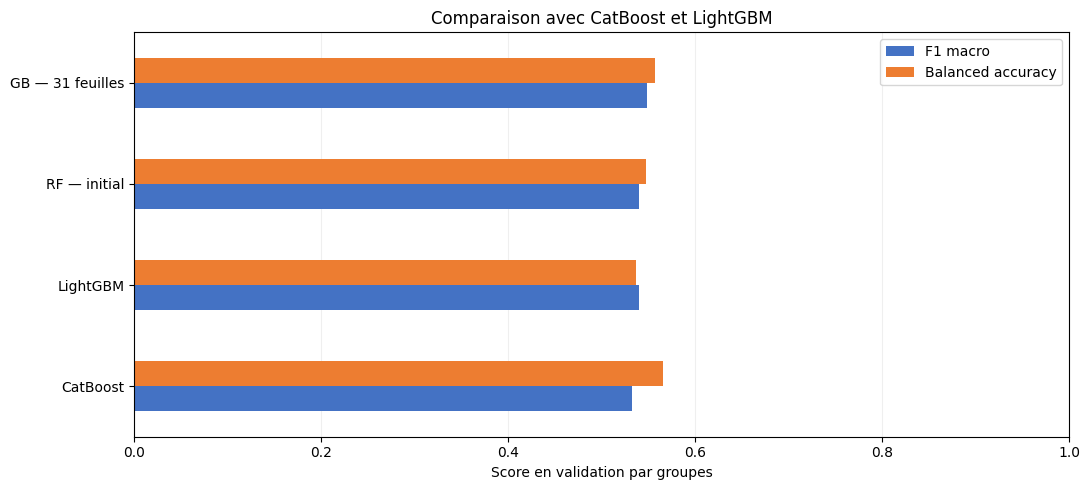


Durée totale : 43.7 minutes


In [18]:
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.utils.class_weight import compute_sample_weight

#### 1. Vérifier les données utilisées
print("Données :", X_app_brut.shape)
print("Étiquettes :", y_actuel.shape)
print("Plis utilisés :", len(plis_actuels))

if not X_app_brut.index.equals(y_actuel.index):
    raise ValueError("Les données et les étiquettes sont désalignées.")


#### 2. Préparer les entrées natives sans encodage en colonnes séparées
def preparer_entrees_natives_actuelles(table):
    resultat = table.copy()

    for colonne in numeriques_modele:
        resultat[colonne] = pd.to_numeric(
            resultat[colonne],
            errors="coerce"
        ).astype("float64")

        resultat[colonne] = resultat[colonne].replace(
            [np.inf, -np.inf], np.nan
        )

    #### CatBoost exige des catégories renseignées sous forme de textes
    for colonne in categorielles_modele:
        resultat[colonne] = (
            resultat[colonne]
            .astype("string")
            .fillna("__manquant__")
            .astype(str)
        )

    return resultat


#### 3. Préparer les catégories LightGBM à partir du pli d'apprentissage
def preparer_lightgbm_actuel(train, validation):
    train_lgbm = train.copy()
    validation_lgbm = validation.copy()
    categories_apprises = {}

    for colonne in categorielles_modele:
        categories = sorted(train_lgbm[colonne].unique().tolist())
        categories_apprises[colonne] = categories

        type_categorie = pd.CategoricalDtype(
            categories=categories,
            ordered=False
        )

        train_lgbm[colonne] = train_lgbm[colonne].astype(type_categorie)

        #### Une catégorie inconnue en validation devient manquante
        validation_lgbm[colonne] = (
            validation_lgbm[colonne].astype(type_categorie)
        )

    return train_lgbm, validation_lgbm, categories_apprises


#### 4. Fixer des réglages de départ pour les deux modèles
parametres_catboost_actuels = {
    "iterations": 500,
    "depth": 6,
    "learning_rate": 0.05,
    "l2_leaf_reg": 5,
    "loss_function": "MultiClass",
    "cat_features": categorielles_modele,
    "nan_mode": "Min",
    "use_best_model": False,
    "random_seed": 42,
    "thread_count": 2,
    "verbose": 100,
    "allow_writing_files": False
}

parametres_lightgbm_actuels = {
    "objective": "multiclass",
    "n_estimators": 500,
    "learning_rate": 0.05,
    "num_leaves": 31,
    "min_child_samples": 30,
    "reg_lambda": 3.0,
    "subsample": 0.8,
    "subsample_freq": 1,
    "colsample_bytree": 0.9,
    "random_state": 42,
    "n_jobs": 2,
    "verbosity": -1,
    "force_col_wise": True
}


#### 5. Initialiser les résultats de cette nouvelle comparaison
predictions_natives_actuelles = {
    nom: pd.Series(index=index_actuel, dtype="object")
    for nom in ["CatBoost", "LightGBM"]
}

details_natifs_actuels = []
modeles_natifs_cv_actuels = []

debut_natifs = time.perf_counter()
numero_entrainement = 0


#### 6. Réutiliser exactement les quatre plis existants
with threadpool_limits(limits=2):

    for numero_pli, (idx_train, idx_validation) in enumerate(plis_actuels, 1):

        train_natif = preparer_entrees_natives_actuelles(
            X_app_brut.iloc[idx_train]
        )

        validation_native = preparer_entrees_natives_actuelles(
            X_app_brut.iloc[idx_validation]
        )

        y_train = y_actuel.iloc[idx_train].to_numpy(dtype=str)
        y_validation = y_actuel.iloc[idx_validation].to_numpy(dtype=str)
        index_validation = index_actuel[idx_validation]

        #### Calculer les poids uniquement avec les classes du pli d'apprentissage
        poids_train = compute_sample_weight(
            class_weight="balanced",
            y=y_train
        )

        for nom in ["CatBoost", "LightGBM"]:
            numero_entrainement += 1

            print(
                f"\n[{numero_entrainement}/8] "
                f"{nom} — pli {numero_pli}/4",
                flush=True
            )

            debut_modele = time.perf_counter()
            categories_apprises = None

            if nom == "CatBoost":
                modele = CatBoostClassifier(
                    **parametres_catboost_actuels
                )

                entrees_train = train_natif
                entrees_validation = validation_native

            else:
                modele = LGBMClassifier(
                    **parametres_lightgbm_actuels
                )

                (
                    entrees_train,
                    entrees_validation,
                    categories_apprises
                ) = preparer_lightgbm_actuel(
                    train_natif,
                    validation_native
                )

            #### Les lignes learn de CatBoost indiquent sa progression d'apprentissage
            #### Le score de validation est calculé après l'entraînement
            modele.fit(
                entrees_train,
                y_train,
                sample_weight=poids_train
            )

            predictions = np.asarray(
                modele.predict(entrees_validation)
            ).reshape(-1).astype(str)

            predictions_natives_actuelles[nom].loc[
                index_validation
            ] = predictions

            scores = calculer_scores_actuels(
                y_validation,
                predictions
            )

            duree = time.perf_counter() - debut_modele

            details_natifs_actuels.append({
                "modele": nom,
                "pli": numero_pli,
                **scores,
                "duree_secondes": duree
            })

            #### Garder les modèles de plis pour une éventuelle interprétation
            modeles_natifs_cv_actuels.append({
                "modele": nom,
                "pli": numero_pli,
                "estimateur": modele,
                "indices_validation": idx_validation.copy(),
                "categories_lightgbm": categories_apprises
            })

            print(
                f"\nVALIDATION — {nom} — pli {numero_pli}/4 : "
                f"F1 macro = {scores['f1_macro']:.3f} | "
                f"Balanced accuracy = {scores['balanced_accuracy']:.3f} | "
                f"Durée = {duree:.1f} s",
                flush=True
            )


#### 7. Ajouter les références déjà évaluées dans ce notebook
predictions_comparaison_native_actuelle = {
    "GB — 31 feuilles": predictions_reglages_actuelles[
        "GB — 31 feuilles"
    ].copy(),

    "RF — initial": predictions_reglages_actuelles[
        "RF — initial"
    ].copy(),

    **predictions_natives_actuelles
}

score_reference_actuel = calculer_scores_actuels(
    y_actuel,
    predictions_comparaison_native_actuelle["GB — 31 feuilles"]
)["f1_macro"]


#### 8. Comparer les scores hors pli
bilan_natif = []
bilan_sources_natif = []

for nom, predictions in predictions_comparaison_native_actuelle.items():

    if not predictions.index.equals(y_actuel.index):
        raise ValueError(f"Alignement incorrect : {nom}")

    if predictions.isna().any():
        raise ValueError(f"Prédictions incomplètes : {nom}")

    scores = calculer_scores_actuels(y_actuel, predictions)

    f1_plis = [
        calculer_scores_actuels(
            y_actuel.iloc[idx_validation],
            predictions.iloc[idx_validation]
        )["f1_macro"]
        for _, idx_validation in plis_actuels
    ]

    bilan_natif.append({
        "modele": nom,
        **scores,
        "gain_f1_sur_gb_actuel": (
            scores["f1_macro"] - score_reference_actuel
        ),
        "f1_moyen_plis": np.mean(f1_plis),
        "ecart_type_f1_plis": np.std(f1_plis, ddof=0)
    })

    for source in ["existant", "neuf"]:
        masque = sources_actuelles.eq(source)

        bilan_sources_natif.append({
            "modele": nom,
            "source": source,
            "classes_evaluees": ", ".join(
                sorted(y_actuel.loc[masque].unique())
            ),
            **calculer_scores_actuels(
                y_actuel.loc[masque],
                predictions.loc[masque]
            )
        })

comparaison_native_actuelle = (
    pd.DataFrame(bilan_natif)
    .sort_values("f1_macro", ascending=False)
    .reset_index(drop=True)
)

comparaison_native_sources_actuelle = (
    pd.DataFrame(bilan_sources_natif)
    .sort_values(["source", "f1_macro"], ascending=[True, False])
    .reset_index(drop=True)
)

print("\nCOMPARAISON GLOBALE — PRÉDICTIONS HORS PLI")
display(comparaison_native_actuelle.round(4))

print("\nRÉSULTATS PAR SOURCE")
display(comparaison_native_sources_actuelle.round(4))


#### 9. Visualiser les scores
ax = (
    comparaison_native_actuelle
    .set_index("modele")[["f1_macro", "balanced_accuracy"]]
    .iloc[::-1]
    .plot(
        kind="barh",
        figsize=(11, 5),
        color=["#4472C4", "#ED7D31"]
    )
)

ax.set_title("Comparaison avec CatBoost et LightGBM")
ax.set_xlabel("Score en validation par groupes")
ax.set_ylabel("")
ax.set_xlim(0, 1)
ax.legend(["F1 macro", "Balanced accuracy"])
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(
    str(DOSSIER_SORTIES / 'comparaison_catboost_lightgbm_actuelle.png'),
    dpi=150,
    bbox_inches="tight"
)
plt.show()


#### 10. Enregistrer les résultats
comparaison_native_actuelle.to_csv(
    str(DOSSIER_SORTIES / 'comparaison_catboost_lightgbm_actuelle.csv'),
    index=False
)

comparaison_native_sources_actuelle.to_csv(
    str(DOSSIER_SORTIES / 'comparaison_sources_catboost_lightgbm_actuelle.csv'),
    index=False
)

pd.DataFrame(details_natifs_actuels).to_csv(
    str(DOSSIER_SORTIES / 'details_plis_catboost_lightgbm_actuels.csv'),
    index=False
)

print(
    "\nDurée totale :",
    round((time.perf_counter() - debut_natifs) / 60, 1),
    "minutes"
)

In [19]:
#### 1. Combiner les prédictions hors pli déjà disponibles
predictions_combinaison_gb31_rf_actuelle = (
    predictions_reglages_actuelles["GB — 31 feuilles"]
    .reindex(y_actuel.index)
    .copy()
)

masque_neuf = sources_actuelles.reindex(y_actuel.index).eq("neuf")

predictions_combinaison_gb31_rf_actuelle.loc[masque_neuf] = (
    predictions_reglages_actuelles["RF — initial"]
    .reindex(y_actuel.index)
    .loc[masque_neuf]
)

#### 2. Comparer les trois stratégies sur les mêmes logements
strategies_combinaison_finale = {
    "GB — 31 feuilles":
        predictions_reglages_actuelles["GB — 31 feuilles"],
    "RF — initial":
        predictions_reglages_actuelles["RF — initial"],
    "GB 31 existant + RF neuf":
        predictions_combinaison_gb31_rf_actuelle,
}

resultats_combinaison_finale = []

for nom, predictions in strategies_combinaison_finale.items():
    predictions = predictions.reindex(y_actuel.index)

    if predictions.isna().any():
        raise ValueError(f"Prédictions manquantes pour {nom}")

    scores = calculer_scores_actuels(y_actuel, predictions)

    scores_plis = [
        calculer_scores_actuels(
            y_actuel.iloc[idx_validation],
            predictions.iloc[idx_validation]
        )["f1_macro"]
        for _, idx_validation in plis_actuels
    ]

    resultats_combinaison_finale.append({
        "strategie": nom,
        **scores,
        "f1_moyen_plis": np.mean(scores_plis),
        "ecart_type_f1_plis": np.std(scores_plis),
    })

#### 3. Afficher le classement
comparaison_combinaison_finale = (
    pd.DataFrame(resultats_combinaison_finale)
    .sort_values("f1_macro", ascending=False)
    .reset_index(drop=True)
)

display(comparaison_combinaison_finale.round(4))

,strategie,accuracy,f1_macro,balanced_accuracy,f1_moyen_plis,ecart_type_f1_plis
0,GB 31 existant + RF neuf,0.6608,0.5549,0.5612,0.5542,0.0188
1,GB — 31 feuilles,0.6455,0.5483,0.5569,0.5479,0.0144
2,RF — initial,0.6526,0.5405,0.5470,0.5397,0.0115


In [20]:
#### 1. Importer les outils nécessaires
import time
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.metrics import cohen_kappa_score
from threadpoolctl import threadpool_limits

#### 2. Vérifier les données et la séparation des groupes
if not X_app_brut.index.equals(y_actuel.index):
    raise ValueError("L'ordre des logements d'apprentissage est incorrect.")

if not X_test_actuel.index.equals(y_test_actuel.index):
    raise ValueError("L'ordre des logements de test est incorrect.")

if set(groupes_app.dropna()) & set(groupes_test.dropna()):
    raise ValueError("Des groupes sont partagés entre apprentissage et test.")

print("Apprentissage :", X_app_brut.shape)
print("Test :", X_test_actuel.shape)
print("Groupes partagés : 0")

#### 3. Entraîner le Random Forest global retenu en validation
pipeline_rf_combinaison_actuelle = Pipeline([
    ("preparation", clone(preparation_actuelle)),
    ("modele", clone(configurations_reglages_actuelles["RF — initial"]))
])

debut = time.perf_counter()
print("\nEntraînement du Random Forest...")

with threadpool_limits(limits=2):
    pipeline_rf_combinaison_actuelle.fit(X_app_brut, y_actuel)

    #### 4. Obtenir les prédictions du GB déjà entraîné
    predictions_gb_test_combinaison = pd.Series(
        np.asarray(
            pipeline_retenu_actuel.predict(X_test_actuel)
        ).reshape(-1).astype(str),
        index=X_test_actuel.index
    )

    #### 5. Utiliser le Random Forest uniquement pour les logements neufs
    predictions_test_combinaison_actuelle = (
        predictions_gb_test_combinaison.copy()
    )

    masque_neuf_test = (
        df_test.loc[X_test_actuel.index, "source_dpe"].eq("neuf")
    )

    predictions_test_combinaison_actuelle.loc[masque_neuf_test] = (
        np.asarray(
            pipeline_rf_combinaison_actuelle.predict(
                X_test_actuel.loc[masque_neuf_test]
            )
        ).reshape(-1).astype(str)
    )

print(f"Calcul terminé en {time.perf_counter() - debut:.1f} secondes.")

#### 6. Comparer le GB et la combinaison sur le même test
ordre_dpe_combinaison = {lettre: i for i, lettre in enumerate("ABCDEFG")}
vrais_rangs = y_test_actuel.map(ordre_dpe_combinaison).to_numpy()

resultats_test_combinaison = []

for nom, predictions in {
    "GB — 31 feuilles": predictions_gb_test_combinaison,
    "GB 31 existant + RF neuf": predictions_test_combinaison_actuelle
}.items():
    scores = calculer_scores_actuels(y_test_actuel, predictions)
    rangs_predits = predictions.map(ordre_dpe_combinaison).to_numpy()
    ecarts = np.abs(vrais_rangs - rangs_predits)

    resultats_test_combinaison.append({
        "strategie": nom,
        **scores,
        "exact_ou_une_classe_ecart": np.mean(ecarts <= 1),
        "ecart_moyen_classes": np.mean(ecarts),
        "kappa_quadratique": cohen_kappa_score(
            vrais_rangs, rangs_predits,
            labels=list(range(7)),
            weights="quadratic"
        )
    })

comparaison_test_combinaison_actuelle = pd.DataFrame(
    resultats_test_combinaison
)

print("\nCOMPARAISON SUR LE TEST")
display(comparaison_test_combinaison_actuelle.round(4))

#### 7. Présenter les résultats de la combinaison par source
resultats_sources_combinaison = []

for source in ["existant", "neuf"]:
    masque = df_test.loc[X_test_actuel.index, "source_dpe"].eq(source)

    resultats_sources_combinaison.append({
        "source": source,
        "logements": int(masque.sum()),
        "classes_evaluees": ", ".join(
            sorted(y_test_actuel.loc[masque].unique())
        ),
        **calculer_scores_actuels(
            y_test_actuel.loc[masque],
            predictions_test_combinaison_actuelle.loc[masque]
        )
    })

print("\nCOMBINAISON : RÉSULTATS PAR SOURCE")
display(pd.DataFrame(resultats_sources_combinaison).round(4))

#### 8. Enregistrer les résultats et les prédictions
comparaison_test_combinaison_actuelle.to_csv(
    str(DOSSIER_SORTIES / 'comparaison_test_combinaison_actuelle.csv'), index=False
)

export_predictions_combinaison = df_test.loc[
    X_test_actuel.index,
    ["numero_dpe", "source_dpe", "etiquette_dpe"]
].copy()

export_predictions_combinaison["prediction_gb"] = (
    predictions_gb_test_combinaison
)
export_predictions_combinaison["prediction_combinaison"] = (
    predictions_test_combinaison_actuelle
)

export_predictions_combinaison.to_csv(
    str(DOSSIER_SORTIES / 'predictions_test_combinaison_actuelle.csv'), index=False
)

print("\nRésultats enregistrés.")

Apprentissage : (15615, 31)
Test : (3891, 31)
Groupes partagés : 0

Entraînement du Random Forest...
Calcul terminé en 8.2 secondes.

COMPARAISON SUR LE TEST


,strategie,accuracy,f1_macro,balanced_accuracy,exact_ou_une_classe_ecart,ecart_moyen_classes,kappa_quadratique
0,GB — 31 feuilles,0.6405,0.5473,0.5673,0.9553,0.4079,0.8802
1,GB 31 existant + RF neuf,0.6577,0.5532,0.5705,0.9584,0.3876,0.8866



COMBINAISON : RÉSULTATS PAR SOURCE


,source,logements,classes_evaluees,accuracy,f1_macro,balanced_accuracy
0,existant,1935,"A, B, C, D, E, F, G",0.5561,0.4895,0.4973
1,neuf,1956,"A, B, C",0.7582,0.6960,0.6937



Résultats enregistrés.


In [21]:
import importlib.util
import json
import platform
import sys
import textwrap
import zipfile
from datetime import datetime, timezone
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import sklearn
from sklearn.metrics import accuracy_score, f1_score, recall_score
from threadpoolctl import threadpool_limits


#### Comparer uniquement les stratégies de classification de cette étude
lignes_validation_publication = []
for nom, pred in strategies_combinaison_finale.items():
    pred = pred.reindex(y_actuel.index)
    if pred.isna().any():
        raise ValueError('Prédictions hors pli incomplètes : ' + nom)
    scores_plis_publication = [
        calculer_scores_actuels(y_actuel.iloc[v], pred.iloc[v])['f1_macro']
        for _, v in plis_actuels
    ]
    lignes_validation_publication.append({
        'methode': nom,
        **metriques_completes_actuelles(y_actuel, pred),
        'f1_moyen_plis': float(np.mean(scores_plis_publication)),
        'ecart_type_f1_plis': float(np.std(scores_plis_publication))
    })
comparaison_validation_publication = pd.DataFrame(lignes_validation_publication)
comparaison_test_publication = comparaison_test_combinaison_actuelle.rename(
    columns={'strategie': 'methode'}
).copy()
lignes_sources_publication = []
for nom, pred in {
    'GB — 31 feuilles': predictions_gb_test_combinaison,
    'GB 31 existant + RF neuf': predictions_test_combinaison_actuelle
}.items():
    for source_publication in ['existant', 'neuf']:
        masque_publication = df_test.loc[y_test_actuel.index, 'source_dpe'].eq(source_publication)
        lignes_sources_publication.append({
            'methode': nom, 'source': source_publication,
            'logements': int(masque_publication.sum()),
            **metriques_completes_actuelles(
                y_test_actuel.loc[masque_publication], pred.loc[masque_publication]
            )
        })
comparaison_sources_publication = pd.DataFrame(lignes_sources_publication)

#### 1. Vérifier que les objets de la comparaison sont disponibles
requis = [
    'pipeline_retenu_actuel', 'pipeline_rf_combinaison_actuelle',
    'X_app_brut', 'X_test_actuel', 'df_app', 'df_test', 'y_actuel',
    'y_test_actuel', 'groupes_app', 'groupes_test',
    'predictions_test_combinaison_actuelle',
    'comparaison_validation_publication', 'comparaison_test_publication',
    'comparaison_sources_publication', 'numeriques_base',
    'numeriques_modele', 'categorielles_modele'
]
absents = [nom for nom in requis if nom not in globals()]
if absents:
    raise RuntimeError('Objets absents : ' + ', '.join(absents))
if set(groupes_app.dropna()) & set(groupes_test.dropna()):
    raise ValueError('Des groupes sont partagés entre apprentissage et test.')
if not X_app_brut.index.equals(y_actuel.index):
    raise ValueError("Ordre de l'apprentissage incorrect.")
if not X_test_actuel.index.equals(y_test_actuel.index):
    raise ValueError('Ordre du test incorrect.')
if not X_app_brut.columns.equals(X_test_actuel.columns):
    raise ValueError('Les variables du test diffèrent de celles de l’apprentissage.')

destination = Path(str(DOSSIER_SORTIES / 'livraison_combinaison_dpe'))
destination.mkdir(parents=True, exist_ok=True)
entrees_brutes = list(numeriques_base) + list(categorielles_modele)
if len(entrees_brutes) != 30 or len(X_app_brut.columns) != 31:
    raise ValueError('Cette livraison attend 30 champs bruts et 31 variables préparées.')

#### 2. Écrire un module autonome de préparation et de prédiction
module_source = '''
import re
import unicodedata
from pathlib import Path
import joblib
import numpy as np
import pandas as pd

NUMERIQUES_BASE = __NUMERIQUES_BASE__
NUMERIQUES = __NUMERIQUES__
CATEGORIELLES = __CATEGORIELLES__
ENTREES = NUMERIQUES_BASE + CATEGORIELLES

def normaliser_modalite(v):
    if pd.isna(v):
        return np.nan
    texte = unicodedata.normalize('NFKD', str(v))
    texte = ''.join(c for c in texte if not unicodedata.combining(c))
    texte = texte.casefold().replace('–', '-').replace('—', '-')
    texte = re.sub(r'\\s+', ' ', texte).strip()
    return texte if texte else np.nan

def preparer_entrees(donnees):
    if isinstance(donnees, dict):
        table = pd.DataFrame([donnees])
    elif isinstance(donnees, pd.DataFrame):
        table = donnees.copy()
    else:
        table = pd.DataFrame(donnees)

    table.columns = [re.sub(r'\\s+', '_', str(c).strip().lower())
                     for c in table.columns]
    if table.columns.duplicated().any():
        raise ValueError('Noms de colonnes en double après normalisation.')
    manquants = [c for c in ['source_dpe', 'type_batiment'] if c not in table]
    if manquants:
        raise ValueError('Champs obligatoires absents : ' + ', '.join(manquants))
    table = table.reindex(columns=ENTREES)
    x = pd.DataFrame(index=table.index)
    for c in NUMERIQUES_BASE:
        x[c] = pd.to_numeric(table[c], errors='coerce').astype('float64')
        x[c] = x[c].replace([np.inf, -np.inf], np.nan)
    for c in CATEGORIELLES:
        x[c] = table[c].map(normaliser_modalite)
    x['volume_habitable_estime_m3'] = (
        x['surface_habitable_logement'] * x['hauteur_sous_plafond']
    )
    for c, choix in [('source_dpe', ['existant', 'neuf']),
                     ('type_batiment', ['maison', 'appartement'])]:
        if not x[c].isin(choix).all():
            raise ValueError(c + ' doit appartenir à : ' + ', '.join(choix))
    return x[NUMERIQUES + CATEGORIELLES]

class ClassificationDPE:
    def __init__(self, modele_existant, modele_neuf, informations):
        self.modeles_ = {'existant': modele_existant, 'neuf': modele_neuf}
        self.informations_ = informations
        self.classes_ = np.array(list('ABCDEFG'))

    def predict(self, donnees):
        x = preparer_entrees(donnees)
        predictions = np.empty(len(x), dtype=object)
        for source, modele in self.modeles_.items():
            masque = x['source_dpe'].eq(source).to_numpy()
            if masque.any():
                predictions[masque] = np.asarray(
                    modele.predict(x.loc[masque])
                ).reshape(-1)
        return predictions

    def predict_proba(self, donnees):
        x = preparer_entrees(donnees)
        probabilites = np.zeros((len(x), len(self.classes_)))
        for source, modele in self.modeles_.items():
            masque = x['source_dpe'].eq(source).to_numpy()
            if masque.any():
                p = modele.predict_proba(x.loc[masque])
                colonnes = [list(self.classes_).index(c) for c in modele.classes_]
                probabilites[np.ix_(np.flatnonzero(masque), colonnes)] = p
        return probabilites

def charger_modele(chemin=None):
    if chemin is None:
        chemin = Path(__file__).parent / 'modele_dpe_combinaison.joblib'
    return joblib.load(chemin)
'''
module_source = module_source.replace('__NUMERIQUES_BASE__', repr(list(numeriques_base)))
module_source = module_source.replace('__NUMERIQUES__', repr(list(numeriques_modele)))
module_source = module_source.replace('__CATEGORIELLES__', repr(list(categorielles_modele)))
chemin_module = destination / 'classification_dpe.py'
chemin_module.write_text(textwrap.dedent(module_source).lstrip(), encoding='utf-8')

spec = importlib.util.spec_from_file_location('classification_dpe', chemin_module)
module_dpe = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = module_dpe
spec.loader.exec_module(module_dpe)

#### 3. Vérifier la préparation sur TOUT l'apprentissage et TOUT le test
for brut, attendu in [(df_app, X_app_brut), (df_test, X_test_actuel)]:
    obtenu = module_dpe.preparer_entrees(brut)
    pd.testing.assert_frame_equal(
        obtenu, attendu, check_dtype=False, check_exact=True
    )
print('Préparation identique à celle évaluée : OUI')

#### 4. Conserver les modèles déjà entraînés et leurs résultats exacts
versions = {
    'numpy': np.__version__, 'pandas': pd.__version__,
    'scikit-learn': sklearn.__version__, 'joblib': joblib.__version__
}
information_livraison = {
    'date_export_utc': datetime.now(timezone.utc).isoformat(),
    'strategie': 'GB 31 feuilles pour existant ; Random Forest pour neuf',
    'regle': {'existant': 'GB — 31 feuilles', 'neuf': 'RF — initial'},
    'n_apprentissage': len(df_app), 'n_test': len(df_test),
    'nombre_champs_bruts': len(entrees_brutes),
    'nombre_variables_preparees': len(X_app_brut.columns),
    'champs_bruts': entrees_brutes,
    'variables_preparees': list(X_app_brut.columns),
    'classes': list('ABCDEFG'),
    'donnees_physiques': 'Variante brute évaluée, sans nouveaux seuils de correction',
    'meteo_externe_requise': False,
    'zone_climatique': 'Champ du DPE parmi les entrées ; peut être manquant',
    'reentrainement_sur_tous_les_logements': False,
    'limite_evaluation': 'Test déjà consulté ; comparaison descriptive, à confirmer sur nouvelles données.',
    'versions': versions, 'python': platform.python_version(),
    'comparaison_validation': comparaison_validation_publication.to_dict(orient='records'),
    'comparaison_test': comparaison_test_publication.to_dict(orient='records')
}
modele_a_livrer = module_dpe.ClassificationDPE(
    pipeline_retenu_actuel,
    pipeline_rf_combinaison_actuelle,
    information_livraison
)
chemin_modele = destination / 'modele_dpe_combinaison.joblib'
joblib.dump(modele_a_livrer, chemin_modele, compress=3)

#### 5. Recharger et vérifier TOUTES les prédictions du test
modele_recharge = module_dpe.charger_modele(chemin_modele)
attendu_test = predictions_test_combinaison_actuelle.reindex(df_test.index)
if attendu_test.isna().any():
    raise ValueError('Prédictions de référence incomplètes.')
with threadpool_limits(limits=2):
    resultat_recharge = modele_recharge.predict(df_test[entrees_brutes])
    probabilites_recharge = modele_recharge.predict_proba(df_test[entrees_brutes])
np.testing.assert_array_equal(resultat_recharge, attendu_test.to_numpy())
np.testing.assert_allclose(probabilites_recharge.sum(axis=1), 1, atol=1e-7)
np.testing.assert_array_equal(
    modele_recharge.classes_[probabilites_recharge.argmax(axis=1)],
    resultat_recharge
)
print(f'Rechargement : {len(df_test)} prédictions identiques sur {len(df_test)}')
print('Probabilités : cohérentes avec les classes prédites')

#### 6. Enregistrer le schéma des entrées et les versions nécessaires
schema = {
    'obligatoires': ['source_dpe', 'type_batiment'],
    'source_dpe': ['existant', 'neuf'],
    'type_batiment': ['maison', 'appartement'],
    'numeriques': list(numeriques_base),
    'categoriels': list(categorielles_modele),
    'unites': {'surface_habitable_logement': 'm²', 'hauteur_sous_plafond': 'm',
               'surface_climatisee': 'm²', 'ubat_w_par_m2_k': 'W/(m².K)'},
    'autres_champs_absents': 'Acceptés ; préparation puis imputation des pipelines entraînés',
    'volume_habitable_estime_m3': 'Calculé automatiquement : surface × hauteur',
    'modalites_nouvelles': 'Traitées par les encodeurs déjà entraînés',
    'consommations_emissions_etiquettes': 'Ne sont pas des entrées du modèle'
}
for nom, contenu in [('informations_modele.json', information_livraison),
                     ('schema_entrees.json', schema)]:
    (destination / nom).write_text(
        json.dumps(contenu, ensure_ascii=False, indent=2), encoding='utf-8'
    )
(destination / 'requirements.txt').write_text(
    '\n'.join(f'{nom}=={version}' for nom, version in versions.items()) + '\n',
    encoding='utf-8'
)

#### 7. Fournir un exemple technique avec des lignes du test
positions_exemple = []
for source in ['existant', 'neuf']:
    positions_exemple.extend(np.flatnonzero(df_test['source_dpe'].eq(source))[:2].tolist())
exemple_entrees = df_test.iloc[positions_exemple][entrees_brutes].copy()
exemple_entrees.to_csv(destination / 'exemple_entrees.csv', index=False)
pd.DataFrame({
    'source_dpe': exemple_entrees['source_dpe'].to_numpy(),
    'prediction_attendue': resultat_recharge[positions_exemple]
}).to_csv(destination / 'exemple_predictions_attendues.csv', index=False)

#### 8. Enregistrer les tableaux et une synthèse pour le rapport
comparaison_validation_publication.to_csv(destination / 'comparaison_validation.csv', index=False)
comparaison_test_publication.to_csv(destination / 'comparaison_test.csv', index=False)
comparaison_sources_publication.to_csv(destination / 'comparaison_sources_test.csv', index=False)

def tableau_markdown_export(table):
    t = table.copy()
    for c in t.select_dtypes(include='number'):
        t[c] = t[c].map(lambda v: f'{v:.4f}')
    lignes = ['| ' + ' | '.join(map(str, t.columns)) + ' |',
              '| ' + ' | '.join(['---'] * len(t.columns)) + ' |']
    lignes += ['| ' + ' | '.join(map(str, row)) + ' |'
               for row in t.itertuples(index=False, name=None)]
    return '\n'.join(lignes)

resume = "# Classification DPE — synthèse\n\n## Données et méthode\n\nLe périmètre conserve 19 506 maisons et appartements parmi deux extractions\nde 10 000 diagnostics chacune. L'apprentissage comprend 15 615 logements,\nl'évaluation 3 891. Aucun groupe détecté n'est partagé entre les deux ensembles.\nLa procédure utilise 31 caractéristiques préparées à partir de 30 champs bruts.\nLes consommations, émissions et étiquettes sont exclues des entrées.\nLa variante physique brute est retenue. Les imputations et encodages sont appris\nsur l'apprentissage de chaque pli. La combinaison utilise le HistGB à 31 feuilles\npour l'existant et le Random Forest pour le neuf, chacun entraîné globalement.\n\n## Comparaison hors pli des stratégies\n\n__TABLE_CV__\n\n## Évaluation descriptive sur la partition réservée\n\n__TABLE_TEST__\n\n## Résultats par source\n\n__TABLE_SOURCES__\n\n## Limites\n\nLe test a été consulté avant certains essais complémentaires et les plis de\nvalidation ont servi à plusieurs choix. Les gains observés doivent être confirmés\nsur de nouvelles données indépendantes. Le F1 du neuf porte sur A, B, C, D, F\nen validation et A, B, C dans l'évaluation. Ces scores par source ne sont donc\npas directement comparables entre les deux ensembles. Le modèle livré conserve\nles ajustements sur 15 615 logements ; il n'est pas réentraîné sur tout le corpus.\nLes probabilités n'ont pas fait l'objet d'une étude de calibration.\n"
colonnes_resume = ['methode', 'accuracy', 'f1_macro', 'balanced_accuracy',
                   'exact_ou_une_classe_ecart', 'ecart_moyen_classes', 'kappa_quadratique']
resume = resume.replace('__TABLE_CV__', tableau_markdown_export(
    comparaison_validation_publication[colonnes_resume]))
resume = resume.replace('__TABLE_TEST__', tableau_markdown_export(
    comparaison_test_publication[colonnes_resume]))
resume = resume.replace('__TABLE_SOURCES__', tableau_markdown_export(
    comparaison_sources_publication))
(destination / 'synthese_classification.md').write_text(resume, encoding='utf-8')

#### 9. Écrire les instructions d'utilisation pour l'étudiant 3
notice = '''# Livraison de la classification DPE

Décompresser ce dossier et installer les versions de requirements.txt.
Depuis ce dossier, utiliser :

```python
import pandas as pd
from classification_dpe import charger_modele

modele = charger_modele()
entrees = pd.read_csv("exemple_entrees.csv")
predictions = modele.predict(entrees)
probabilites = modele.predict_proba(entrees)
print(predictions)
print(modele.classes_)  # ordre des colonnes de probabilités : A à G
```

Pour un seul logement : `modele.predict({"source_dpe": "existant",
"type_batiment": "appartement", "surface_habitable_logement": 65,
"hauteur_sous_plafond": 2.5})`.
Ce format minimal illustre l'appel ; renseigner les autres caractéristiques
connues améliore la qualité des informations fournies au modèle.

Le module prépare les données, calcule le volume et sélectionne le modèle.
Ne pas encoder ou imputer manuellement les entrées avant de les lui transmettre.
Les probabilités sont des sorties du modèle ; leur calibration n'a pas été évaluée.
Le schéma des 30 champs bruts est fourni dans schema_entrees.json.
Les exemples sont des lignes du jeu de test et ne constituent pas une nouvelle évaluation.
Les prédictions attendues des exemples sont fournies pour contrôler l'intégration.
Les résultats et limites figurent dans synthese_classification.md.
Les modèles exportés ont été entraînés sur 15 615 logements.
Ce dossier ne contient pas d'API de service ni de collecte météo à exécuter.
'''
(destination / 'LIRE_MOI.md').write_text(notice, encoding='utf-8')

#### 10. Vérifier aussi la lecture du CSV d'exemple après export
exemple_relu = pd.read_csv(destination / 'exemple_entrees.csv')
np.testing.assert_array_equal(
    modele_recharge.predict(exemple_relu), resultat_recharge[positions_exemple]
)
information_livraison['verification_export'] = {
    'preparation_apprentissage_et_test_identique': True,
    'predictions_identiques_sur_tout_le_test': True,
    'nombre_predictions_verifiees': len(df_test),
    'probabilites_coherentes': True,
    'exemple_csv_relu_identique': True
}
# Le modèle et son fichier JSON portent les mêmes informations de vérification.
modele_a_livrer.informations_ = information_livraison
joblib.dump(modele_a_livrer, chemin_modele, compress=3)
with threadpool_limits(limits=2):
    np.testing.assert_array_equal(
        module_dpe.charger_modele(chemin_modele).predict(df_test[entrees_brutes]),
        attendu_test.to_numpy()
    )
(destination / 'informations_modele.json').write_text(
    json.dumps(information_livraison, ensure_ascii=False, indent=2), encoding='utf-8'
)

#### 11. Créer une archive contenant uniquement les fichiers de livraison
fichiers_livraison = [
    'classification_dpe.py', 'modele_dpe_combinaison.joblib',
    'informations_modele.json', 'schema_entrees.json', 'requirements.txt',
    'exemple_entrees.csv', 'exemple_predictions_attendues.csv',
    'comparaison_validation.csv', 'comparaison_test.csv',
    'comparaison_sources_test.csv', 'synthese_classification.md', 'LIRE_MOI.md'
]
archive = Path(str(DOSSIER_SORTIES / 'livraison_combinaison_dpe.zip'))
with zipfile.ZipFile(archive, 'w', compression=zipfile.ZIP_DEFLATED) as z:
    for nom in fichiers_livraison:
        z.write(destination / nom, arcname=nom)

print('\nEXPORT TERMINÉ ET VÉRIFIÉ')
print('Modèles : GB pour existant ; Random Forest pour neuf')
print('Apprentissage conservé :', len(df_app), 'logements')
print('Champs bruts : 30 ; variables préparées : 31')
print('Fichiers dans le ZIP :', len(fichiers_livraison))
print('Archive :', archive)
print(f'Taille : {archive.stat().st_size / 1024**2:.2f} Mo')

#### 12. Proposer le téléchargement du ZIP depuis Colab
if DANS_COLAB:
    from google.colab import files
    files.download(str(archive))
else:
    print('Archive disponible localement :', archive)


Préparation identique à celle évaluée : OUI
Rechargement : 3891 prédictions identiques sur 3891
Probabilités : cohérentes avec les classes prédites

EXPORT TERMINÉ ET VÉRIFIÉ
Modèles : GB pour existant ; Random Forest pour neuf
Apprentissage conservé : 15615 logements
Champs bruts : 30 ; variables préparées : 31
Fichiers dans le ZIP : 12
Archive : /content/outputs_classification/livraison_combinaison_dpe.zip
Taille : 26.40 Mo


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>